# Laboratorio 3 · Caja de herramientas de anonimización

**Atacar → Medir → Transformar → Comparar → Decidir → Entregar**

Leyes, Ética y Protección de Datos · Especialización en Análisis Estadístico para Ciencia de Datos · Docente: Wilson Sandoval Rodríguez

---

> **Versión con soluciones.** Material de apoyo docente. Incluye respuestas orientativas y las celdas ya ejecutadas.

> Todos los datos son **sintéticos**. Ninguna persona real está representada.


## «Anonimícenla y se la mandamos el viernes»

El proveedor del motor de recomendación pide la base de DataMarket. En este
laboratorio usted va a hacer **lo que casi nadie hace antes de entregar una
base**: atacarla, medirla, transformarla con varias técnicas y decidir con
números.

| | |
|:--|:--|
| **Aprenderá a** | Aplicar ocho técnicas de protección, medir el riesgo y la utilidad que deja cada una, y sostener una decisión de entrega |
| **Duración** | ≈ 45 minutos en clase (ruta 🟢) · el resto se completa en la Actividad 4 |
| **Evidencia** | Bitácora de técnicas, comparación riesgo-pérdida-utilidad, base entregable y dictamen generado |
| **Unidad** | 3 · Técnicas de protección, IA y datos masivos |

### Mapa del laboratorio

| Parte | Qué pasa | Ruta | Tiempo |
|:--|:--|:--:|:--:|
| **0 · Preparar** | Cargar datos y la caja de herramientas | 🟢 | 2 min |
| **1 · Atacar** | Reidentificamos clientes con una sola línea de código | 🟢 | 6 min |
| **2 · Medir** | *k*-anonimato, *l*-diversidad y riesgo 1/*k* | 🟢 | 7 min |
| **3 · Transformar** | Estaciones 1–4 (eliminar, sustituir, generalizar, suprimir) | 🟢 | 15 min |
| | Estaciones 5–8 (colas, ruido, privacidad diferencial, sintéticos) | 🔵 | 25 min |
| **4 · Comparar** | Riesgo, pérdida y utilidad de cinco versiones | 🟢 | 8 min |
| **5 · Decidir y entregar** | Verificación automática + dictamen | 🟢 | 5 min |
| **6 · Reflexionar** | Big Data, IA y una regla para el decálogo | 🔵 | 10 min |

🟢 **En clase** (≈ 45 min) · 🔵 **Profundización** en casa o en la Actividad 4.
Todas las celdas se ejecutan igual: las 🔵 se pueden correr sin detenerse a
responder y volver después.

> 🎛️ Las celdas marcadas con **PERILLA** tienen parámetros para mover. Cámbielos,
> vuelva a ejecutar y mire qué pasa. Ese es el laboratorio.

---

# 0 · PREPARAR

In [1]:
from pathlib import Path
import pandas as pd

# Funciona en tres sitios sin cambiar nada:
#   - dentro del repositorio (labs/ o raíz)
#   - en Google Colab
#   - en cualquier equipo con internet
RUTA = Path("../data/clientes_sinteticos.csv")
if not RUTA.exists():
    RUTA = Path("data/clientes_sinteticos.csv")
if not RUTA.exists():
    RUTA = "https://raw.githubusercontent.com/wilsonsr/leyes-etica-proteccion-datos/main/data/clientes_sinteticos.csv"

print("Origen de los datos:", RUTA)

Origen de los datos: ../data/clientes_sinteticos.csv


In [2]:
import hashlib
import hmac
import secrets
import warnings

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

df = pd.read_csv(RUTA)
# Recencia en días: más útil para el modelo que una fecha.
df["recencia_dias"] = (
    pd.to_datetime(df["fecha_ultima_compra"]).max() - pd.to_datetime(df["fecha_ultima_compra"])
).dt.days

print(f"Registros: {len(df):,}   Variables: {df.shape[1]}")
df.head(3)

Registros: 1,512   Variables: 36


,cliente_id,nombre,email,telefono,documento,fecha_nacimiento,edad,sexo,ciudad,barrio,direccion,latitud,longitud,estrato,ocupacion,ingresos_mensuales,dispositivo,ip,pais_residencia,canal_adquisicion,origen_dato,fecha_autorizacion,consentimiento_marketing,visitas_web,productos_vistos,categoria_top,compras_6m,monto_compras,fecha_ultima_compra,compras_farmacia_6m,entrega_asistida,busquedas_maternidad,score_riesgo_interno,segmento,churn,recencia_dias
0,DM-00865,Luis Castro,luis.castro806@mail.co,3361052437,SYN-92480821,1992-12-31,33,M,Barranquilla,Simon Bolivar,Carrera 7 # 58-18,10.97607,-74.80194,2.0,Pensionado/a,2460000.0,Android,135.169.205.166,Colombia,email_marketing,lista_comprada_tercero,NaN,0,12,36,moda,2,418000.0,2026-08-29,0,0,0,26,fiel,0,1
1,DM-00714,Paula Beltran,paula.beltran226@correo.com,3552777695,SYN-95884611,1974-01-01,52,F,Cartagena,Manga,Carrera 53 # 50-88,10.33459,-75.45909,1.0,Comerciante,1710000.0,iOS,192.175.234.41,Colombia,publicidad_pagada,registro_cuenta,2024-02-23,1,9,28,supermercado,4,778000.0,2026-05-11,1,0,0,48,estable,0,111
2,DM-00572,Alvaro Riveros,alvaro.riveros457@mail.co,3693537285,SYN-35266492,2000-12-31,25,F,Barranquilla,El Prado,Diagonal 42 # 18-58,10.95000,-74.77236,3.0,Comerciante,2950000.0,Android,57.79.150.169,Alemania,publicidad_pagada,programa_fidelizacion,2025-05-14,1,12,19,tecnologia,2,435000.0,2026-07-26,0,0,0,41,estable,0,35


### La caja de herramientas

La celda siguiente define todas las funciones del laboratorio. **No necesita
modificarla**, pero vale la pena leerla: son unas 120 líneas y ninguna es magia.

| Función | Para qué sirve |
|:--|:--|
| `perfil_riesgo()` | *k* mínimo, % de registros con *k*=1 y *k*<5, riesgo medio 1/*k* y *l*-diversidad, para un escenario de atacante |
| `grafico_grupos()` | Cuántos registros quedan en grupos de tamaño 1, 2, 3–4, 5–9 y 10+ |
| `ataque_vinculacion()` | Cruza una fuente pública con la base liberada y cuenta a quién reidentifica |
| `generalizar()` | Generaliza edad, sexo, ciudad, ocupación y estrato con perillas |
| `ncp()` | Pérdida de información: 0 % si el dato es exacto, 100 % si se suprime |
| `utilidad_cv()` | AUC del modelo de abandono en 5 pliegues, comparable entre versiones y sin fugas |
| `dif_tasas()` | Cuánto cambia la tasa de abandono por categoría (puntos porcentuales) |
| `registrar()` | Anota cada paso en la **bitácora** que alimenta el dictamen final |

In [3]:
# ===================== CAJA DE HERRAMIENTAS · no necesita modificarla =====================
from sklearn.metrics import roc_auc_score

COLOR = {"antes": "#94a3b8", "despues": "#0891b2", "alerta": "#dc2626",
         "ok": "#16a34a", "acento": "#7c3aed", "ambar": "#d97706"}
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlesize": 12, "font.size": 10})

# Dos escenarios de atacante. Hay que DECLARAR cuál se mide: k depende de él.
CUASI = ["edad", "sexo", "ciudad", "ocupacion"]       # escenario básico
CUASI_AMPLIADO = CUASI + ["estrato"]                   # + estrato (se deduce de la dirección)
SENSIBLE = "categoria_top"                             # lo que no queremos revelar
K_OBJETIVO = 5                                         # umbral de referencia del curso (no es legal)
COLS_MODELO = ["edad", "sexo", "ciudad", "ocupacion", "estrato", "visitas_web", "productos_vistos",
               "compras_6m", "monto_compras", "recencia_dias", "canal_adquisicion", "categoria_top"]


def tam_grupo(datos, cuasi):
    # Tamaño del grupo de equivalencia al que pertenece cada registro.
    return datos.assign(_u=1).groupby(cuasi, dropna=False, observed=True)["_u"].transform("size")


def perfil_riesgo(datos, cuasi=CUASI, sensible=SENSIBLE, k=K_OBJETIVO):
    tam = tam_grupo(datos, cuasi)
    res = {
        "registros": len(datos),
        "combinaciones": int(datos.groupby(cuasi, dropna=False, observed=True).ngroups),
        "k mínimo": int(tam.min()),
        "% k=1": round((tam == 1).mean() * 100, 1),
        f"% k<{k}": round((tam < k).mean() * 100, 1),
        # Riesgo del «fiscal»: el atacante SABE que la persona está en la base y elige al azar en su grupo.
        "riesgo medio 1/k %": round((1 / tam).mean() * 100, 1),
    }
    if sensible is not None and sensible in datos.columns:
        l = datos.groupby(cuasi, dropna=False, observed=True)[sensible].transform("nunique")
        res["l mínimo"] = int(l.min())
        # Grupos con k>=2 donde todos comparten el valor sensible: identidad protegida, atributo expuesto.
        res["% homogéneos (k≥2)"] = round(((l == 1) & (tam >= 2)).mean() * 100, 1)
    return res


def grafico_grupos(versiones, cuasi=CUASI, titulo="¿En qué tamaño de grupo queda cada persona?"):
    cortes = [0, 1, 2, 4, 9, np.inf]
    etiquetas = ["k=1\n(sola)", "k=2", "k=3–4", "k=5–9", "k≥10"]
    fig, ax = plt.subplots()
    ancho = 0.8 / len(versiones)
    paleta = [COLOR["antes"], COLOR["despues"], COLOR["acento"], COLOR["ambar"], COLOR["ok"]]
    for i, (nombre, datos) in enumerate(versiones.items()):
        tam = tam_grupo(datos, cuasi)
        pct = pd.cut(tam, cortes, labels=etiquetas).value_counts(normalize=True).reindex(etiquetas) * 100
        x = np.arange(len(etiquetas)) + i * ancho - 0.4 + ancho / 2
        barras = ax.bar(x, pct.values, ancho, label=nombre, color=paleta[i % len(paleta)])
        ax.bar_label(barras, fmt="%.0f%%", fontsize=8, padding=2)
    ax.axvspan(-0.5, 2.5, color=COLOR["alerta"], alpha=0.06)
    ax.text(1, ax.get_ylim()[1] * 0.92, "zona de riesgo (k<5)", ha="center", color=COLOR["alerta"], fontsize=9)
    ax.set_xticks(range(len(etiquetas)), etiquetas)
    ax.set_ylabel("% de registros")
    ax.set_title(titulo + f"\n(atacante conoce: {', '.join(cuasi)})", fontsize=11)
    ax.legend(frameon=False)
    plt.show()


def ataque_vinculacion(publica, liberada, claves, mostrar=True):
    # publica: nombre + claves (+ _verdad solo para verificar el experimento).
    # liberada: claves + lo que se entregó (+ _verdad, que el atacante NO ve).
    publica = publica.reset_index(drop=True).rename_axis("_pid").reset_index()
    cruce = publica.merge(liberada, on=claves, how="inner", suffixes=("_pub", "_lib"))
    candidatos = cruce.groupby("_pid")["_verdad_lib"].transform("size")
    unicos = cruce[candidatos == 1]
    aciertos = unicos[unicos["_verdad_pub"] == unicos["_verdad_lib"]]
    tam = publica.merge(liberada.groupby(claves, dropna=False).size().rename("k").reset_index(),
                        on=claves, how="left")["k"]
    prob = (1 / tam).fillna(0).mean() * 100   # quien fue suprimido no puede ser acertado: aporta 0
    res = {"personas en la fuente pública": len(publica),
           "reidentificadas con certeza (k=1)": len(aciertos),
           "% reidentificadas": round(len(aciertos) / len(publica) * 100, 1),
           "acierto esperado adivinando 1/k %": round(prob, 1)}
    if mostrar:
        print("ATAQUE DE VINCULACIÓN · claves:", ", ".join(claves))
        for k_, v_ in res.items():
            print(f"  {k_:<36}: {v_}")
    return res, aciertos


REGIONES = {
    "Bogota": "Centro", "Ibague": "Centro", "Villavicencio": "Centro",
    "Medellin": "Antioquia-Eje", "Pereira": "Antioquia-Eje", "Manizales": "Antioquia-Eje",
    "Cali": "Pacífico", "Pasto": "Pacífico",
    "Barranquilla": "Caribe", "Cartagena": "Caribe", "Santa Marta": "Caribe",
    "Bucaramanga": "Nororiente",
}
GRUPOS_OCUPACION = {
    "Ingeniero/a": "técnico-profesional", "Tecnico/a": "técnico-profesional",
    "Disenador/a": "técnico-profesional", "Contador/a": "técnico-profesional",
    "Abogado/a": "técnico-profesional", "Administrador/a": "técnico-profesional",
    "Docente": "servicios", "Enfermero/a": "servicios",
    "Comerciante": "servicios", "Independiente": "servicios",
    "Estudiante": "sin actividad remunerada", "Pensionado/a": "sin actividad remunerada",
}
NIVELES_ESTRATO = {1: "bajo (1-2)", 2: "bajo (1-2)", 3: "medio (3-4)", 4: "medio (3-4)", 5: "alto (5-6)", 6: "alto (5-6)"}


def generalizar(datos, edad=10, sexo="agrupar", ciudad="region", ocupacion="grupo", estrato="exacto"):
    # edad: 0 (exacta), 5, 10 o 20 años  ·  sexo: "conservar" | "agrupar" | "suprimir"
    # ciudad: "ciudad" | "region" | "suprimir"  ·  ocupacion: "exacta" | "grupo" | "suprimir"
    # estrato: "exacto" | "nivel" (bajo/medio/alto) | "suprimir"
    d = datos.copy()
    if edad:
        ini = (d["edad"] // edad * edad).astype(int)
        d["edad"] = ini.astype(str) + "–" + (ini + edad - 1).astype(str)
    if sexo == "agrupar":
        d["sexo"] = d["sexo"].replace({"Otro": "Otro/NR", "Prefiere no responder": "Otro/NR"})
    elif sexo == "suprimir":
        d["sexo"] = "*"
    if ciudad == "region":
        d["ciudad"] = d["ciudad"].map(REGIONES)
    elif ciudad == "suprimir":
        d["ciudad"] = "*"
    if ocupacion == "grupo":
        d["ocupacion"] = d["ocupacion"].map(GRUPOS_OCUPACION)
    elif ocupacion == "suprimir":
        d["ocupacion"] = "*"
    if "estrato" in d.columns:
        if estrato == "nivel":
            d["estrato"] = d["estrato"].map(NIVELES_ESTRATO).fillna("sin dato")
        elif estrato == "suprimir":
            d["estrato"] = "*"
    return d


def ncp(version, original=None, cuasi=CUASI_AMPLIADO):
    # Pérdida de información (NCP, 0–100 %). Para cada registro y cuasi-identificador:
    #   (valores originales que caben en su clase − 1) / (valores posibles − 1)
    # 0 = dato exacto · 100 = dato suprimido. Un registro eliminado cuenta como 100.
    original = df if original is None else original
    perdidas = []
    for c in cuasi:
        o = original[c].astype(str)
        dominio = o.nunique()
        v = version[c].reindex(original.index).astype(str)
        clase = o.groupby(v).transform("nunique")
        p = (clase - 1) / (dominio - 1)
        p[~original.index.isin(version.index)] = 1.0
        perdidas.append(p)
    return round(float(pd.concat(perdidas, axis=1).mean().mean() * 100), 1)


def dif_tasas(version, var="categoria_top"):
    # Mayor diferencia (puntos porcentuales) en la tasa de abandono por categoría, versión vs. original.
    orig = df.groupby(var)["churn"].mean()
    nueva = version.groupby(var)["churn"].mean().reindex(orig.index)
    return round(float((nueva - orig).abs().max() * 100), 1)


def _matriz(d, columnas, ref=None):
    X = pd.get_dummies(d[columnas], dtype=float)
    return X if ref is None else X.reindex(columns=ref, fill_value=0)


def utilidad_cv(transformar=None, suprimir_en=None, sintetico=None, semilla=42):
    # AUC del modelo de abandono, comparable entre versiones y SIN fugas:
    #  · los mismos 5 pliegues para todas las versiones (comparación pareada);
    #  · la transformación, la supresión o el generador se ajustan SOLO con el entrenamiento;
    #  · se evalúa siempre en personas reales que no se usaron, transformadas con la misma regla.
    cv = StratifiedKFold(5, shuffle=True, random_state=semilla)
    aucs = []
    for i_tr, i_te in cv.split(df, df["churn"]):
        tr, te = df.iloc[i_tr], df.iloc[i_te]
        if sintetico is not None:
            tr_t, te_t = sintetico(tr), te
        else:
            tr_t = transformar(tr) if transformar else tr
            if suprimir_en:
                tr_t = tr_t[tam_grupo(tr_t, suprimir_en) >= K_OBJETIVO]
            te_t = transformar(te) if transformar else te
        if len(tr_t) < 50 or tr_t["churn"].nunique() < 2:
            aucs.append(np.nan)   # la supresión dejó muy pocos registros para entrenar
            continue
        Xtr = _matriz(tr_t, COLS_MODELO)
        mediana = Xtr.median()
        Xtr = Xtr.fillna(mediana)
        Xte = _matriz(te_t, COLS_MODELO, Xtr.columns).fillna(mediana)
        modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
        modelo.fit(Xtr, tr_t["churn"])
        aucs.append(roc_auc_score(te["churn"], modelo.predict_proba(Xte)[:, 1]))
    aucs = np.array(aucs)
    if np.isnan(aucs).any():
        print("⚠️  Con esta versión la supresión deja demasiados pocos registros para entrenar: AUC no disponible.")
    return aucs


BITACORA = []


def registrar(paso, datos, tecnica, nota=""):
    b = perfil_riesgo(datos, CUASI)
    a = perfil_riesgo(datos, CUASI_AMPLIADO) if "estrato" in datos.columns else {}
    fila = {"paso": paso, "técnica": tecnica, "registros": b["registros"],
            "k mín. (básico)": b["k mínimo"], "% k<5 (básico)": b["% k<5"],
            "% k<5 (+estrato)": a.get("% k<5", np.nan), "riesgo 1/k % (+estrato)": a.get("riesgo medio 1/k %", np.nan),
            "% homogéneos": b["% homogéneos (k≥2)"], "NCP %": ncp(datos), "nota": nota}
    BITACORA[:] = [x for x in BITACORA if x["paso"] != paso] + [fila]
    return pd.DataFrame(BITACORA).set_index("paso")


print("Caja de herramientas lista ✔")

Caja de herramientas lista ✔


---

# 1 · ATACAR

*Antes de proteger una base, intente romperla.*

### La versión «anonimizada» que casi todo el mundo entrega

Borramos nombre, correo, teléfono, documento y dirección. Es lo que se suele
llamar «anonimizar».

In [4]:
IDENTIFICADORES_DIRECTOS = ["nombre", "email", "telefono", "documento", "direccion"]

base_ingenua = df.drop(columns=IDENTIFICADORES_DIRECTOS).copy()
base_ingenua["_verdad"] = df["cliente_id"]   # solo para verificar el experimento

print(f"Quedan {base_ingenua.shape[1] - 1} variables. Ningún nombre a la vista.")
base_ingenua[CUASI + ["compras_farmacia_6m", "busquedas_maternidad", "categoria_top"]].head()

Quedan 31 variables. Ningún nombre a la vista.


,edad,sexo,ciudad,ocupacion,compras_farmacia_6m,busquedas_maternidad,categoria_top
0,33,M,Barranquilla,Pensionado/a,0,0,moda
1,52,F,Cartagena,Comerciante,1,0,supermercado
2,25,F,Barranquilla,Comerciante,0,0,tecnologia
3,37,F,Bucaramanga,Pensionado/a,0,0,moda
4,58,M,Pereira,Disenador/a,4,0,tecnologia


### El atacante

Alguien tiene una **fuente pública**: perfiles profesionales, una lista de
egresados, una publicación en redes. En ella aparecen 300 clientes con su
nombre, edad, sexo, ciudad y ocupación. Nada secreto. También anotó el
**estrato**, que se deduce de una dirección: lo usaremos más adelante.

In [5]:
rng = np.random.default_rng(2026)
muestra = rng.choice(len(df), size=300, replace=False)

fuente_publica = df.iloc[muestra][["nombre"] + CUASI + ["estrato"]].copy()
fuente_publica["_verdad"] = df.iloc[muestra]["cliente_id"].values   # el atacante no lo ve

fuente_publica.drop(columns="_verdad").head()

,nombre,edad,sexo,ciudad,ocupacion,estrato
1465,Carlos Peralta,41,M,Bogota,Enfermero/a,3.0
1414,Santiago Moreno,32,F,Cali,Tecnico/a,3.0
489,Tatiana Barrios,39,M,Bogota,Abogado/a,3.0
433,Mateo Solano,69,M,Bogota,Comerciante,3.0
748,Claudia Cardenas,56,F,Bucaramanga,Tecnico/a,3.0


In [6]:
# El ataque completo es esta línea:
cruce = fuente_publica.merge(base_ingenua, on=CUASI)

res_ingenua, reidentificados = ataque_vinculacion(fuente_publica, base_ingenua, CUASI)

print("\nLo que ahora sabemos de cinco personas con nombre propio:")
reidentificados[["nombre", "edad", "ciudad", "categoria_top",
                 "compras_farmacia_6m", "busquedas_maternidad", "entrega_asistida"]].head()

ATAQUE DE VINCULACIÓN · claves: edad, sexo, ciudad, ocupacion
  personas en la fuente pública       : 300
  reidentificadas con certeza (k=1)   : 248
  % reidentificadas                   : 82.7
  acierto esperado adivinando 1/k %   : 91.0

Lo que ahora sabemos de cinco personas con nombre propio:


,nombre,edad,ciudad,categoria_top,compras_farmacia_6m,busquedas_maternidad,entrega_asistida
0,Carlos Peralta,41,Bogota,hogar,1,0,1
1,Santiago Moreno,32,Cali,moda,0,1,0
2,Tatiana Barrios,39,Bogota,tecnologia,1,0,0
3,Mateo Solano,69,Bogota,libros,3,0,1
8,Angela Guerrero,47,Medellin,mascotas,1,0,0


> ### 🔴 Riesgo · Pregunta 1
>
> Con una sola línea de `merge`, ¿qué porcentaje de las 300 personas quedó reidentificado **con certeza**?
>
> Mire las columnas de la derecha: `busquedas_maternidad`, `compras_farmacia_6m`, `entrega_asistida`. ¿Qué podría inferir alguien sobre esas personas? ¿Seguiría llamando «anonimizada» a esta base?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Cerca del 80 % de la fuente pública queda reidentificada con certeza (el número exacto aparece en la salida). Las columnas de la derecha permiten inferir embarazo, una condición de salud o una discapacidad: datos sensibles que nadie recogió como tales. La base **no** está anonimizada; solo está **desnominalizada**. Es el mismo mecanismo de los casos de Sweeney (1997), AOL (2006) y Netflix (2008).

</details>

**Mi respuesta:** …

---

# 2 · MEDIR

*Anonimizar es un resultado que se mide, no una operación que se aplica.*

### Tres ideas en una tabla de ocho filas

Antes de mirar 1 512 registros, mire ocho. Los **cuasi-identificadores** son
edad y ciudad; el **atributo sensible** es la categoría que más compra.

In [7]:
juguete = pd.DataFrame({
    "edad":      ["30–39", "30–39", "30–39", "40–49", "40–49", "40–49", "50–59", "50–59"],
    "ciudad":    ["Caribe", "Caribe", "Caribe", "Centro", "Centro", "Centro", "Centro", "Pacífico"],
    "categoria": ["salud", "moda", "hogar", "maternidad", "maternidad", "maternidad", "libros", "salud"],
})
juguete["k (tamaño del grupo)"] = tam_grupo(juguete, ["edad", "ciudad"])
juguete["l (valores sensibles distintos)"] = (
    juguete.groupby(["edad", "ciudad"])["categoria"].transform("nunique"))
juguete

,edad,ciudad,categoria,k (tamaño del grupo),l (valores sensibles distintos)
0,30–39,Caribe,salud,3,3
1,30–39,Caribe,moda,3,3
2,30–39,Caribe,hogar,3,3
3,40–49,Centro,maternidad,3,1
4,40–49,Centro,maternidad,3,1
5,40–49,Centro,maternidad,3,1
6,50–59,Centro,libros,1,1
7,50–59,Pacífico,salud,1,1


| Concepto | Pregunta que responde | En la tabla |
|:--|:--|:--|
| ***k*-anonimato** | ¿Con cuántas personas me confundo? | Las dos últimas filas tienen *k* = 1: están solas |
| ***l*-diversidad** | Aunque me confunda, ¿se sabe mi dato sensible? | El grupo 40–49 · Centro tiene *k* = 3 pero *l* = 1: las tres compran maternidad |
| **Riesgo 1/*k*** | Si el atacante busca a alguien y elige al azar dentro de su grupo, ¿cuánto acierta? | Un tercio en el grupo de tres; certeza en los de uno |

### Lo que estas métricas dicen y lo que no dicen

- **1/*k* es una probabilidad condicional, no universal.** Supone que el atacante
  **sabe que la persona está en la base** (el «modelo del fiscal») y que elige al
  azar dentro del grupo. Si no sabe si está, el riesgo es menor; si tiene
  información adicional, mayor.
- ***k* depende del escenario.** *k* se calcula para un conjunto declarado de
  cuasi-identificadores. Si el atacante conoce una variable más que viaja en la
  base, el *k* real puede ser mucho menor. Por eso este laboratorio mide **dos
  escenarios**.
- **Cumplir *k* ≥ 5 no es una garantía de anonimización.** No protege el
  atributo (homogeneidad), ni de la vinculación por otras columnas, ni de
  cruces futuros. Es un umbral de trabajo que hay que **declarar y justificar**.
- **La *l*-diversidad cuenta valores distintos, no su peso.** Un grupo con nueve
  «maternidad» y una «moda» tiene *l* = 2, pero revela el atributo con 90 % de
  confianza. Existen variantes (entrópica, *t*-cercanía) que miden la
  concentración; aquí basta con saber que *l* > 1 no es suficiente por sí sola.

In [8]:
linea_base = registrar("0 · sin identificadores directos", base_ingenua,
                       "supresión de 5 columnas",
                       nota="lo que casi todos entregan")
linea_base

,técnica,registros,k mín. (básico),% k<5 (básico),% k<5 (+estrato),riesgo 1/k % (+estrato),% homogéneos,NCP %,nota
paso,,,,,,,,,
0 · sin identificadores directos,supresión de 5 columnas,1512,1,100.0,100.0,97.8,3.2,0.0,lo que casi todos entregan


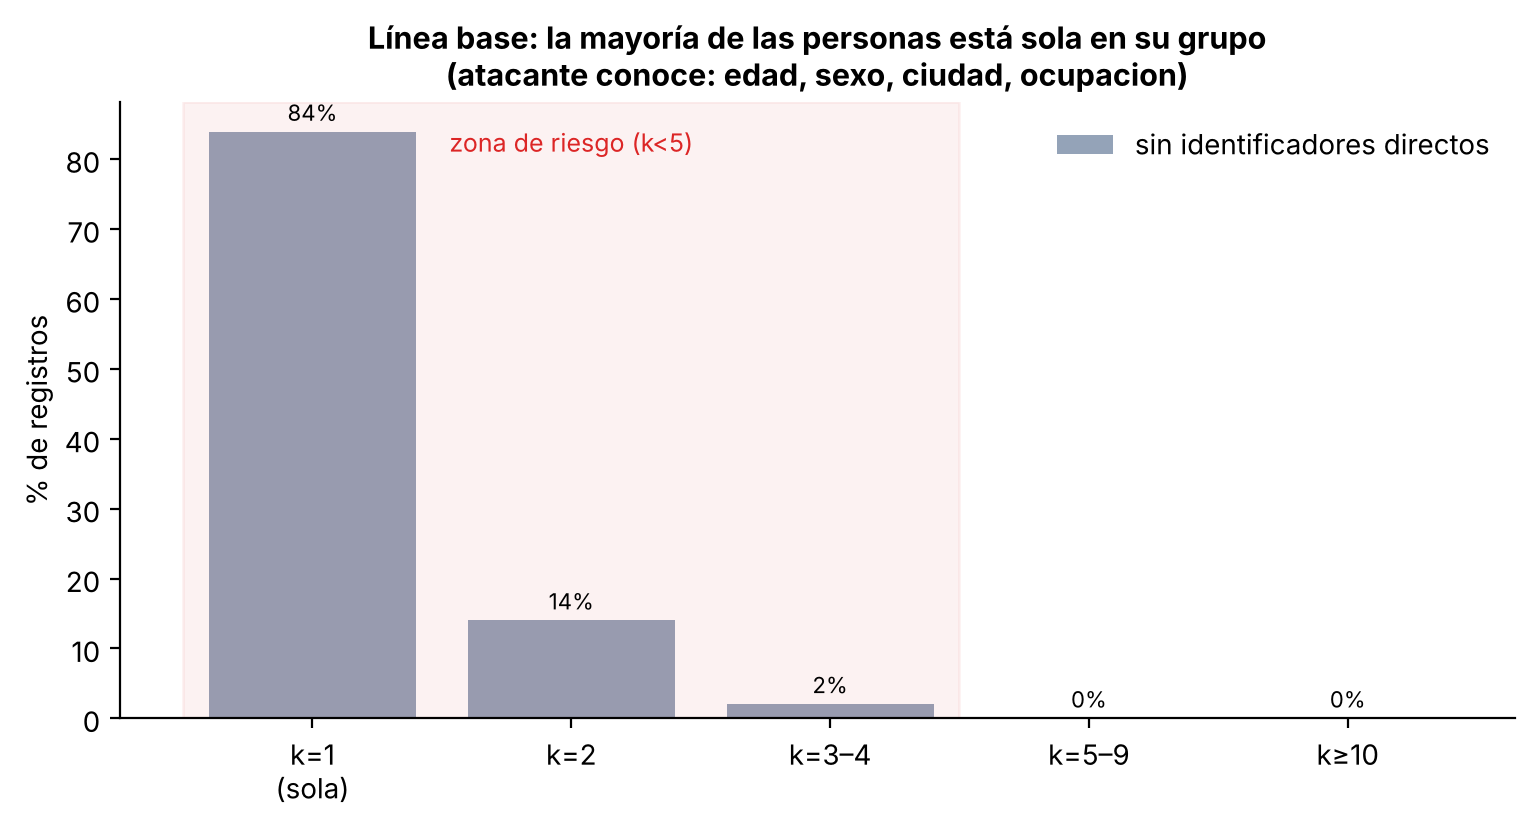

In [9]:
grafico_grupos({"sin identificadores directos": base_ingenua},
               titulo="Línea base: la mayoría de las personas está sola en su grupo")

> ### 🟡 Decida · Pregunta 2
>
> La línea base da un *k* mínimo de 1 y un porcentaje alto en *k* = 1. Ahora mire la última columna: `% homogéneos (k≥2)`.
>
> Explique con sus palabras por qué una persona puede estar **protegida en su identidad** y **expuesta en su atributo sensible** al mismo tiempo.

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Si todos los miembros de un grupo comparten el valor sensible, el atacante no necesita saber cuál de ellos es la persona: le basta con saber que está en el grupo. Es el **ataque de homogeneidad**. Por eso *k*-anonimato no basta y se mide también *l*-diversidad.

</details>

**Mi respuesta:** …

---

# 3 · TRANSFORMAR

*Ocho estaciones. En cada una: qué hace la técnica, qué protege, qué cuesta.*

| # | Estación | Familia |
|:--:|:--|:--|
| 1 | Supresión de identificadores indirectos | Eliminar |
| 2 | Seudonimización: *hash* ingenuo frente a HMAC con clave | Sustituir |
| 3 | Generalización con perillas | Reducir detalle |
| 4 | Supresión local de grupos pequeños | Eliminar |
| 5 | *Top/bottom coding* y microagregación | Reducir detalle |
| 6 | Perturbación: ruido y coordenadas | Alterar |
| 7 | Privacidad diferencial para tablas agregadas | Alterar con garantía |
| 8 | Datos sintéticos | Reemplazar |

## 🟢 🧰 Estación 1 · Supresión de identificadores indirectos

`ip`, `latitud`, `longitud` y `dispositivo` no tienen nombre, pero apuntan a
una persona o a una casa. Y el motor de recomendación no los necesita.

In [10]:
INDIRECTOS = ["ip", "latitud", "longitud", "dispositivo", "barrio", "fecha_nacimiento"]
# fecha_nacimiento es otra forma de la edad; barrio es ubicación fina.

e1 = base_ingenua.drop(columns=INDIRECTOS)
print("Columnas suprimidas:", ", ".join(INDIRECTOS))
print(f"Variables que quedan: {e1.shape[1] - 1}")

# ¿Qué habría pasado si el atacante también conociera el barrio?
for cols in [CUASI, CUASI + ["barrio"], CUASI + ["barrio", "estrato"]]:
    p = perfil_riesgo(df, cols, sensible=None)
    print(f"{' + '.join(cols):<52} -> {p['% k=1']:>5} % de personas solas")

Columnas suprimidas: ip, latitud, longitud, dispositivo, barrio, fecha_nacimiento
Variables que quedan: 25


edad + sexo + ciudad + ocupacion                     ->  83.9 % de personas solas
edad + sexo + ciudad + ocupacion + barrio            ->  94.3 % de personas solas
edad + sexo + ciudad + ocupacion + barrio + estrato  ->  97.9 % de personas solas


> ### 🟡 Decida · Pregunta 3
>
> Suprimir estas columnas **no cambia** el riesgo medido con los cuatro cuasi-identificadores. Entonces, ¿para qué sirvió?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Cierra otras puertas de ataque que la métrica con cuatro variables no ve: la IP y las coordenadas permiten vincular con registros de navegación o con un mapa; sumar `barrio` dispara la proporción de personas solas (vea la salida). La métrica mide un escenario de ataque, no todos. Por eso hay que **declarar el escenario** (qué sabe el atacante) en el informe.

</details>

**Mi respuesta:** …

## 🟢 🧰 Estación 2 · Seudonimización: el *hash* no es un escudo

El proveedor necesita una clave para unir compras del mismo cliente. Tentación:
reemplazar el documento por su *hash* SHA-256. Veamos qué pasa si alguien
tiene **otra base con documentos** (una filtración, una base comprada).

In [11]:
def hash_ingenuo(valor):
    return hashlib.sha256(str(valor).encode("utf-8")).hexdigest()[:16]

# Lo que se entrega
entrega_hash = pd.DataFrame({"id_hash": df["documento"].map(hash_ingenuo),
                             "categoria_top": df["categoria_top"]})

# Lo que tiene el atacante: 400 documentos con nombre, de otra fuente
otra_base = df.sample(400, random_state=7)[["documento", "nombre"]]
otra_base["id_hash"] = otra_base["documento"].map(hash_ingenuo)   # ¡el algoritmo es público!

revertidos = otra_base.merge(entrega_hash, on="id_hash").drop_duplicates("documento")
print(f"Hash ingenuo: {len(revertidos)} de 400 personas reidentificadas")
revertidos[["nombre", "documento", "id_hash", "categoria_top"]].head(4)

Hash ingenuo: 399 de 400 personas reidentificadas


,nombre,documento,id_hash,categoria_top
0,Natalia Trujillo,SYN-25882091,02488e0c85486338,hogar
1,Sandra Pineda,SYN-23482868,0a50dad3011fce59,tecnologia
2,Lorena Guerrero,SYN-26615928,5c0f0f845b8f9b0d,libros
3,Ximena Martinez,SYN-18242764,f286eff1087b00e5,mascotas


In [12]:
# HMAC: hash con una CLAVE SECRETA que nunca sale de DataMarket.
CLAVE_SECRETA = secrets.token_bytes(32)   # en producción: gestor de secretos, rotación, acceso por rol

def seudonimo_hmac(valor, clave=CLAVE_SECRETA):
    return hmac.new(clave, str(valor).encode("utf-8"), hashlib.sha256).hexdigest()[:16]

entrega_hmac = pd.DataFrame({"id_seudo": df["documento"].map(seudonimo_hmac),
                             "categoria_top": df["categoria_top"]})
otra_base["id_seudo"] = otra_base["documento"].map(hash_ingenuo)  # el atacante no tiene la clave
print("HMAC sin la clave:", otra_base.merge(entrega_hmac, on="id_seudo")["documento"].nunique(),
      "de 400 personas reidentificadas")

# ¿Y si la clave se filtra? El HMAC es tan fuerte como la custodia de la clave.
otra_base["id_filtrado"] = otra_base["documento"].map(seudonimo_hmac)
print("HMAC con la clave filtrada:", otra_base.merge(entrega_hmac, left_on="id_filtrado",
      right_on="id_seudo")["documento"].nunique(), "de 400 personas reidentificadas")

HMAC sin la clave: 0 de 400 personas reidentificadas
HMAC con la clave filtrada: 399 de 400 personas reidentificadas


> ### 🔴 Riesgo · Pregunta 4
>
> Con HMAC el cruce dio cero. ¿Significa que la base seudonimizada ya es **anónima**?
>
> Piense en dos cosas: quién tiene la clave y qué pasa con los cuasi-identificadores de la parte 1.

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

No. Primero, DataMarket conserva la clave y la tabla de equivalencias: puede revertir el seudónimo, así que los datos siguen siendo personales (el GDPR lo dice expresamente en el considerando 26). Segundo, el seudónimo solo protege la columna del identificador: el ataque de vinculación por edad, sexo, ciudad y ocupación sigue funcionando igual. Tercero, el seudónimo es **determinista**: la misma persona tiene el mismo código en todas las entregas, así que dos entregas se pueden unir entre sí (vinculabilidad). En 2014 se publicaron 173 millones de viajes de taxi de Nueva York con las placas «protegidas» con MD5 sin clave; se revirtieron en horas.

</details>

**Mi respuesta:** …

## 🟢 🧰 Estación 3 · Generalización con perillas 🎛️

Reducir el detalle de los cuasi-identificadores: edad exacta → rango; ciudad →
región; ocupación → grupo. **Mueva las perillas** y vuelva a ejecutar. Busque
la combinación más útil que deje menos del 5 % de los registros con *k* < 5.

In [13]:
# ===================== PERILLA =====================
NIVEL_EDAD     = 10          # 0 = exacta · 5 · 10 · 20 años
SEXO_COMO      = "agrupar"   # "conservar" · "agrupar" · "suprimir"
CIUDAD_COMO    = "region"    # "ciudad" · "region" · "suprimir"
OCUPACION_COMO = "suprimir"  # "exacta" · "grupo" · "suprimir"
ESTRATO_COMO   = "nivel"     # "exacto" · "nivel" (bajo/medio/alto) · "suprimir"
# ===================================================

e3 = generalizar(e1, NIVEL_EDAD, SEXO_COMO, CIUDAD_COMO, OCUPACION_COMO, ESTRATO_COMO)
registrar("3 · generalización (mía)", e3, "generalización",
          nota=f"edad {NIVEL_EDAD} · sexo {SEXO_COMO} · {CIUDAD_COMO} · ocupación {OCUPACION_COMO} · estrato {ESTRATO_COMO}")

,técnica,registros,k mín. (básico),% k<5 (básico),% k<5 (+estrato),riesgo 1/k % (+estrato),% homogéneos,NCP %,nota
paso,,,,,,,,,
0 · sin identificadores directos,supresión de 5 columnas,1512,1,100.0,100.0,97.8,3.2,0.0,lo que casi todos entregan
3 · generalización (mía),generalización,1512,1,4.6,20.3,17.5,0.1,30.0,edad 10 · sexo agrupar · region · ocupación su...


**Cómo leer la bitácora.** Hay dos columnas de riesgo porque hay dos
escenarios: el **básico** (el atacante conoce edad, sexo, ciudad y ocupación) y
el **ampliado** (además conoce el estrato, que se deduce de una dirección).
`NCP %` es la **pérdida de información**: 0 si el dato se entrega exacto, 100 si
se suprime. Una versión es mejor que otra solo si tiene **menos riesgo y menos
pérdida a la vez**.

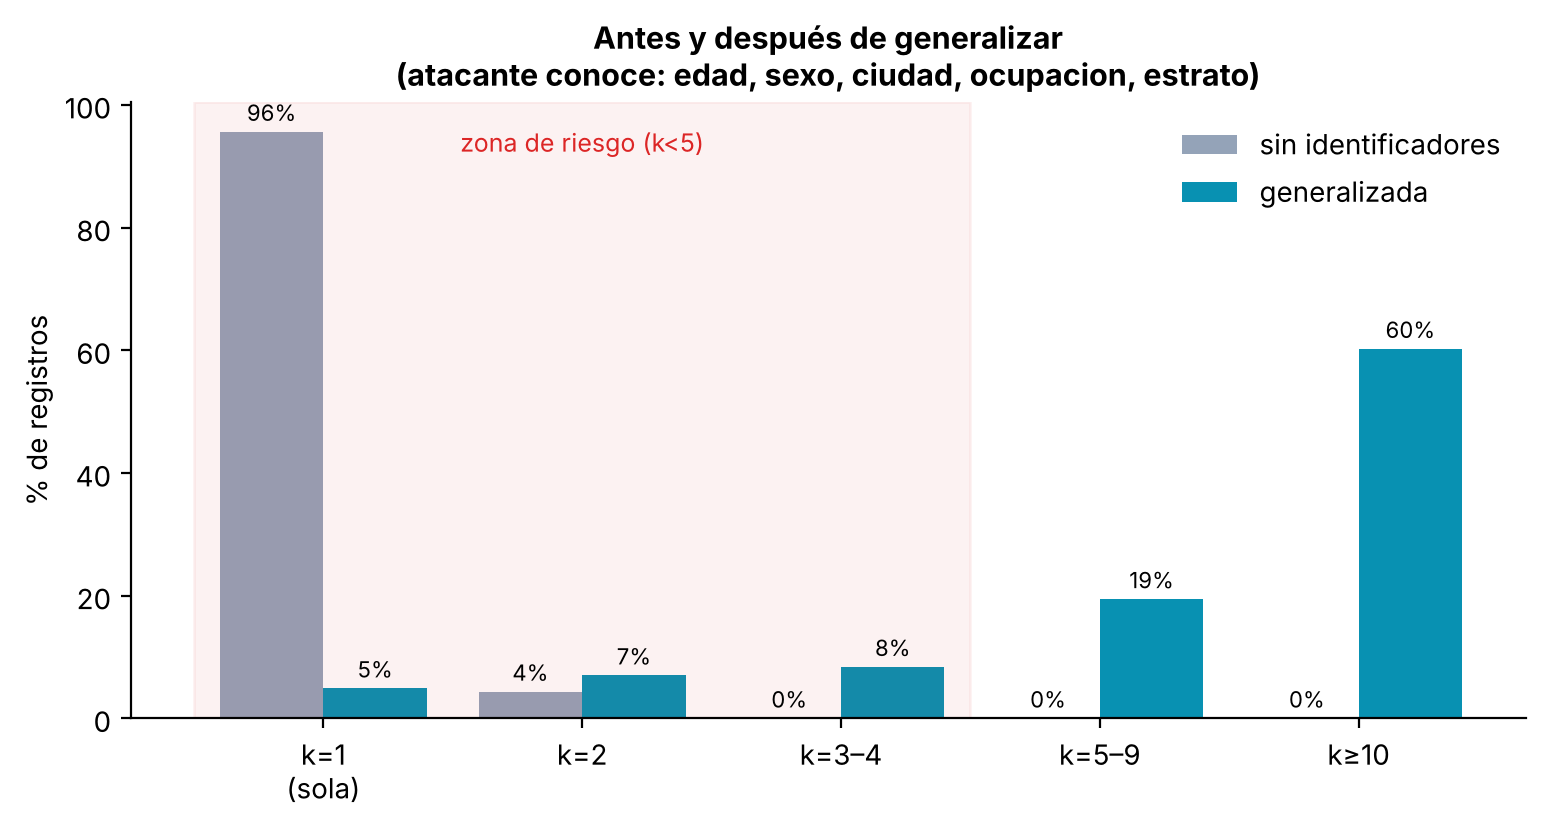

In [14]:
grafico_grupos({"sin identificadores": base_ingenua, "generalizada": e3}, cuasi=CUASI_AMPLIADO,
               titulo="Antes y después de generalizar")

### Todas las combinaciones de una vez

En lugar de probar a mano, recorramos las **324 combinaciones** de perillas y
midamos cada una en el escenario ampliado. Cada punto es una versión posible de
la base. Los puntos unidos por la línea forman la **frontera de Pareto**: las
versiones que ninguna otra supera en riesgo **y** pérdida al mismo tiempo. Las
demás son decisiones dominadas: hay otra mejor en los dos ejes.

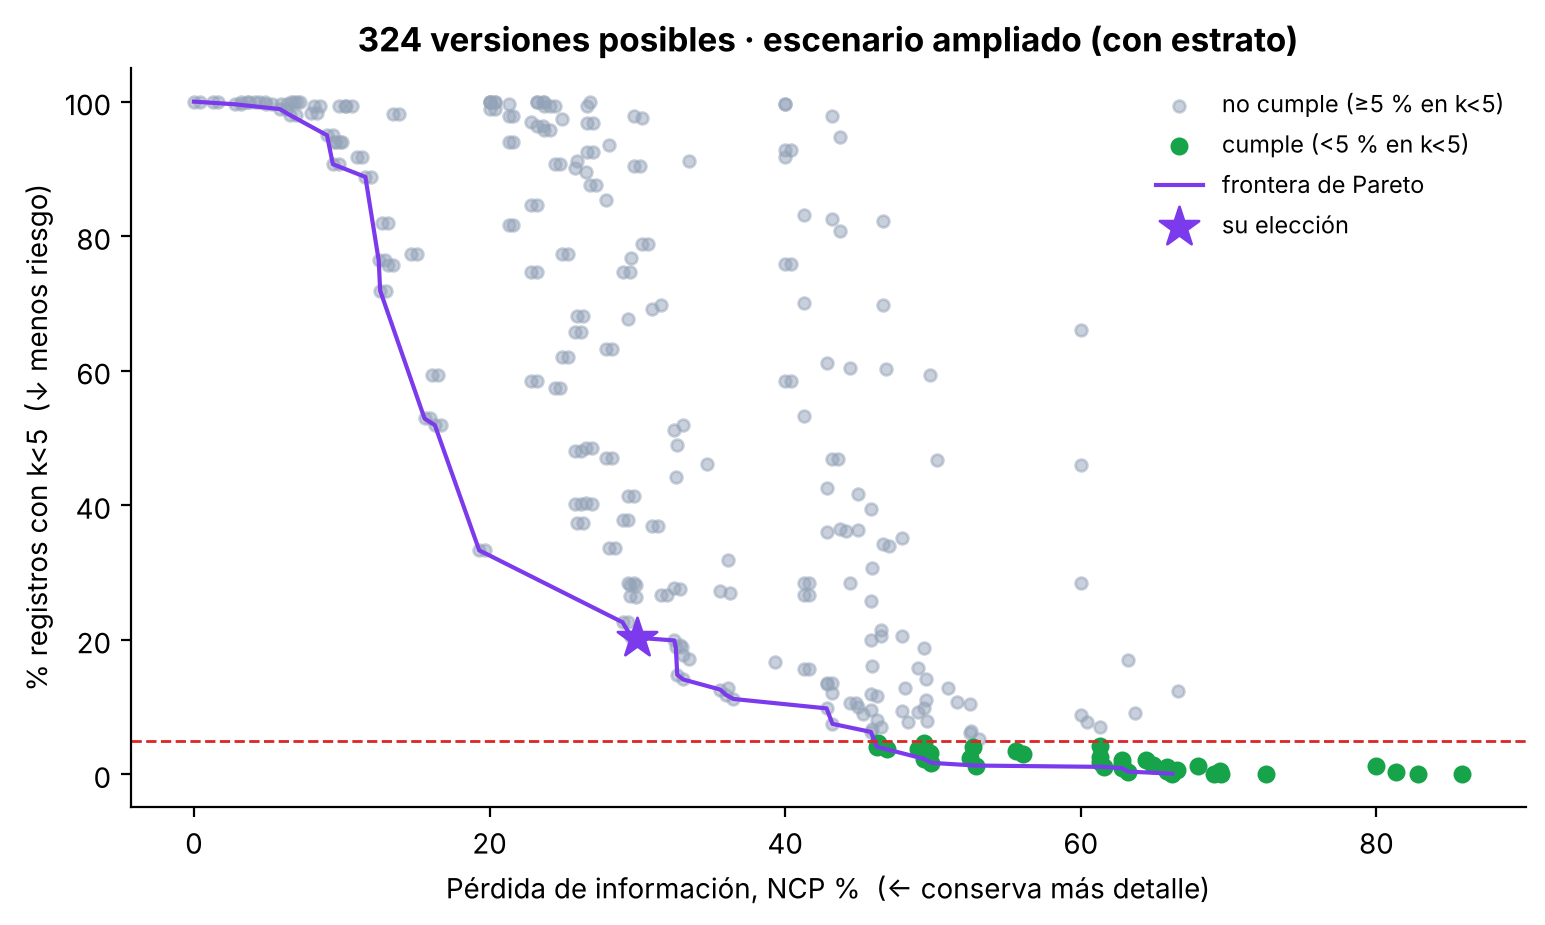

Las cinco versiones que cumplen con MENOS pérdida de información:


,edad,sexo,ciudad,ocupacion,estrato,% k<5,NCP %,pareto
294,20,agrupar,suprimir,suprimir,exacto,4.1,46.2,True
206,10,agrupar,region,suprimir,suprimir,4.6,46.3,False
214,10,agrupar,suprimir,suprimir,nivel,3.7,46.9,True
260,20,conservar,region,suprimir,suprimir,3.8,49.0,False
185,10,conservar,suprimir,grupo,suprimir,4.7,49.4,False


In [15]:
import itertools

filas = []
for ed, sx, ci, oc, es in itertools.product([0, 5, 10, 20], ["conservar", "agrupar", "suprimir"],
                                            ["ciudad", "region", "suprimir"], ["exacta", "grupo", "suprimir"],
                                            ["exacto", "nivel", "suprimir"]):
    g = generalizar(e1, ed, sx, ci, oc, es)
    filas.append({"edad": ed, "sexo": sx, "ciudad": ci, "ocupacion": oc, "estrato": es,
                  "% k<5": perfil_riesgo(g, CUASI_AMPLIADO, sensible=None)["% k<5"], "NCP %": ncp(g)})
mapa = pd.DataFrame(filas)

# Frontera de Pareto: nadie tiene a la vez menos riesgo y menos pérdida.
orden = mapa.sort_values(["NCP %", "% k<5"])
mapa["pareto"] = False
mejor = np.inf
for i, fila in orden.iterrows():
    if fila["% k<5"] < mejor:
        mapa.loc[i, "pareto"] = True
        mejor = fila["% k<5"]

fig, ax = plt.subplots(figsize=(9, 4.8))
ok = mapa["% k<5"] < 5
ax.scatter(mapa.loc[~ok, "NCP %"], mapa.loc[~ok, "% k<5"], color=COLOR["antes"], alpha=.5, s=18, label="no cumple (≥5 % en k<5)")
ax.scatter(mapa.loc[ok, "NCP %"], mapa.loc[ok, "% k<5"], color=COLOR["ok"], s=30, label="cumple (<5 % en k<5)")
fr = mapa[mapa["pareto"]].sort_values("NCP %")
ax.plot(fr["NCP %"], fr["% k<5"], "-", color=COLOR["acento"], lw=1.5, label="frontera de Pareto")
mia = mapa[(mapa.edad == NIVEL_EDAD) & (mapa.sexo == SEXO_COMO) & (mapa.ciudad == CIUDAD_COMO)
           & (mapa.ocupacion == OCUPACION_COMO) & (mapa.estrato == ESTRATO_COMO)]
ax.scatter(mia["NCP %"], mia["% k<5"], color=COLOR["acento"], s=220, marker="*", label="su elección", zorder=5)
ax.axhline(5, color=COLOR["alerta"], ls="--", lw=1)
ax.set_xlabel("Pérdida de información, NCP %  (← conserva más detalle)")
ax.set_ylabel("% registros con k<5  (↓ menos riesgo)")
ax.set_title("324 versiones posibles · escenario ampliado (con estrato)")
ax.legend(frameon=False, fontsize=8.5)
plt.show()

print("Las cinco versiones que cumplen con MENOS pérdida de información:")
mapa[ok].sort_values("NCP %").head(5)

#### 🎮 Panel interactivo (Colab o Jupyter)

Si está en Colab o Jupyter con `ipywidgets`, la celda siguiente crea un panel
con menús. Si no, muestra una tabla fija. Funciona igual en los dos casos.

In [16]:
def panel(edad=10, sexo="agrupar", ciudad="region", ocupacion="grupo", estrato="nivel"):
    g = generalizar(e1, edad, sexo, ciudad, ocupacion, estrato)
    b, a = perfil_riesgo(g, CUASI), perfil_riesgo(g, CUASI_AMPLIADO)
    semaforo = "🟢" if a["% k<5"] < 5 else ("🟡" if a["% k<5"] < 20 else "🔴")
    print(f"{semaforo}  k<5: {b['% k<5']} % (básico) · {a['% k<5']} % (+estrato)  ·  "
          f"homogéneos {a['% homogéneos (k≥2)']} %  ·  pérdida NCP {ncp(g)} %")

try:
    from ipywidgets import interact
    interact(panel, edad=[0, 5, 10, 20], sexo=["conservar", "agrupar", "suprimir"],
             ciudad=["ciudad", "region", "suprimir"], ocupacion=["exacta", "grupo", "suprimir"],
             estrato=["exacto", "nivel", "suprimir"])
except ImportError:
    for ed in [0, 5, 10, 20]:
        print(f"edad={ed:>2}", end="  ")
        panel(ed)

edad= 0  🔴  k<5: 90.5 % (básico) · 98.1 % (+estrato)  ·  homogéneos 4.4 %  ·  pérdida NCP 13.9 %
edad= 5  🔴  k<5: 36.9 % (básico) · 77.3 % (+estrato)  ·  homogéneos 3.2 %  ·  pérdida NCP 15.1 %
edad=10  🔴  k<5: 18.9 % (básico) · 51.9 % (+estrato)  ·  homogéneos 2.4 %  ·  pérdida NCP 16.7 %
edad=20  🔴  k<5: 11.8 % (básico) · 33.3 % (+estrato)  ·  homogéneos 1.3 %  ·  pérdida NCP 19.7 %


> ### 🟡 Decida · Pregunta 5
>
> Mire la frontera de Pareto. ¿Qué perillas aparecen en casi todas las versiones de la frontera? Si el proveedor necesita recomendar **por ciudad**, ¿qué tendría que sacrificar a cambio?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

En la frontera dominan la edad en rangos amplios y el estrato en niveles o suprimido: son las variables que más separan a las personas. Conservar la ciudad obliga a compensar con más generalización en edad, ocupación o estrato. La lección: **la finalidad decide qué variable se sacrifica**, y la frontera muestra el precio de cada elección. Elegir un punto fuera de la frontera es pagar pérdida o riesgo sin necesidad.

</details>

**Mi respuesta:** …

## 🟢 🧰 Estación 4 · Supresión local: quitar a los que quedan solos

Después de generalizar suele quedar un puñado de personas en grupos pequeños.
Una salida es **suprimir esos registros**. Parece gratis. No lo es.

*La supresión se calcula en el escenario ampliado (con estrato): es el más
exigente de los dos que declaramos.*

In [17]:
tam = tam_grupo(e3, CUASI_AMPLIADO)
e4 = e3[tam >= K_OBJETIVO].copy()
suprimidos = e3[tam < K_OBJETIVO]

print(f"Registros suprimidos: {len(suprimidos)} ({len(suprimidos)/len(e3)*100:.1f} %)")
registrar("4 · + supresión local k<5", e4, "supresión de registros",
          nota=f"{len(suprimidos)} registros fuera")

Registros suprimidos: 307 (20.3 %)


,técnica,registros,k mín. (básico),% k<5 (básico),% k<5 (+estrato),riesgo 1/k % (+estrato),% homogéneos,NCP %,nota
paso,,,,,,,,,
0 · sin identificadores directos,supresión de 5 columnas,1512,1,100.0,100.0,97.8,3.2,0.0,lo que casi todos entregan
3 · generalización (mía),generalización,1512,1,4.6,20.3,17.5,0.1,30.0,edad 10 · sexo agrupar · region · ocupación su...
4 · + supresión local k<5,supresión de registros,1205,5,0.0,0.0,8.2,0.0,44.3,307 registros fuera


In [18]:
# ¿Los suprimidos son una muestra al azar? Se comparan con sus datos ORIGINALES.
def rasgos(idx):
    o = df.loc[idx]
    return [o["churn"].mean(), o["sexo"].isin(["Otro", "Prefiere no responder"]).mean(),
            (o["pais_residencia"] != "Colombia").mean(), (o["edad"] >= 60).mean(),
            o["estrato"].isin([5, 6]).mean()]

comparacion = pd.DataFrame(
    {"se quedan": rasgos(e4.index), "se suprimen": rasgos(suprimidos.index)},
    index=["tasa de abandono", "sexo: otro / no responde", "residente fuera de Colombia",
           "60 años o más", "estratos 5 y 6"]) * 100
comparacion["diferencia (pp)"] = comparacion["se suprimen"] - comparacion["se quedan"]
print(f"La tasa de abandono por categoría cambia hasta {dif_tasas(e4)} puntos porcentuales "
      "respecto a la base completa.")
comparacion.round(1)

La tasa de abandono por categoría cambia hasta 6.8 puntos porcentuales respecto a la base completa.


,se quedan,se suprimen,diferencia (pp)
tasa de abandono,27.2,29.0,1.8
sexo: otro / no responde,0.5,27.4,26.9
residente fuera de Colombia,10.5,7.5,-3.0
60 años o más,1.2,22.1,20.9
estratos 5 y 6,14.8,33.9,19.1


> ### 🔴 Riesgo · Pregunta 6
>
> ¿A quién se lleva la supresión? Mire la columna `diferencia (pp)`. Si el proveedor entrena con la base sin esas personas, ¿para quién va a funcionar peor el recomendador? ¿Y qué le pasa a una estadística como la tasa de abandono?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

La supresión se lleva sobre todo a las minorías de la base: personas que no se identifican como F o M, mayores, residentes fuera del país, estratos poco frecuentes. Proteger su identidad borrándolas las vuelve **invisibles** para el modelo: es un sesgo de representación fabricado por la anonimización (enlace directo con el Encuentro 3). Además cambia las tasas que se calculen después. Alternativas: suprimir celdas (reemplazar por `*`) en lugar de filas, o generalizar más solo para esos grupos. Y siempre **reportar cuántos y quiénes** se suprimieron.

</details>

**Mi respuesta:** …

## 🔵 🧰 Estación 5 · *Top coding* y microagregación

Los ingresos tienen una cola larga: una persona que gana 22 millones es casi
única aunque todo lo demás esté generalizado.

- ***Top/bottom coding***: todo lo que pase del percentil 95 se registra como el percentil 95.
- **Microagregación**: se ordena, se forman grupos de *k* personas y se reemplaza el valor por el promedio del grupo.

In [19]:
def top_bottom(s, inf=0.05, sup=0.95):
    return s.clip(s.quantile(inf), s.quantile(sup))

def microagregar(s, k=K_OBJETIVO):
    s = s.copy()
    validos = s.dropna().sort_values()
    grupo = np.arange(len(validos)) // k
    grupo[grupo == grupo.max()] = max(grupo.max() - 1, 0) if (grupo == grupo.max()).sum() < k else grupo.max()
    s.loc[validos.index] = validos.groupby(grupo).transform("mean").values
    return s

ingresos = e4["ingresos_mensuales"]
versiones_ing = pd.DataFrame({
    "original": ingresos,
    "top/bottom 5 %": top_bottom(ingresos),
    "microagregado k=5": microagregar(ingresos),
})

resumen = versiones_ing.agg(["mean", "median", "std", "max", "nunique"]).T
resumen.columns = ["media", "mediana", "desv. est.", "máximo", "valores distintos"]
resumen.style.format("{:,.0f}")

,media,mediana,desv. est.,máximo,valores distintos
original,"3,314,211","2,680,000","2,344,167","22,410,000",498
top/bottom 5 %,"3,183,573","2,680,000","1,815,795","7,844,000",419
microagregado k=5,"3,314,211","2,680,000","2,332,955","17,342,857",219


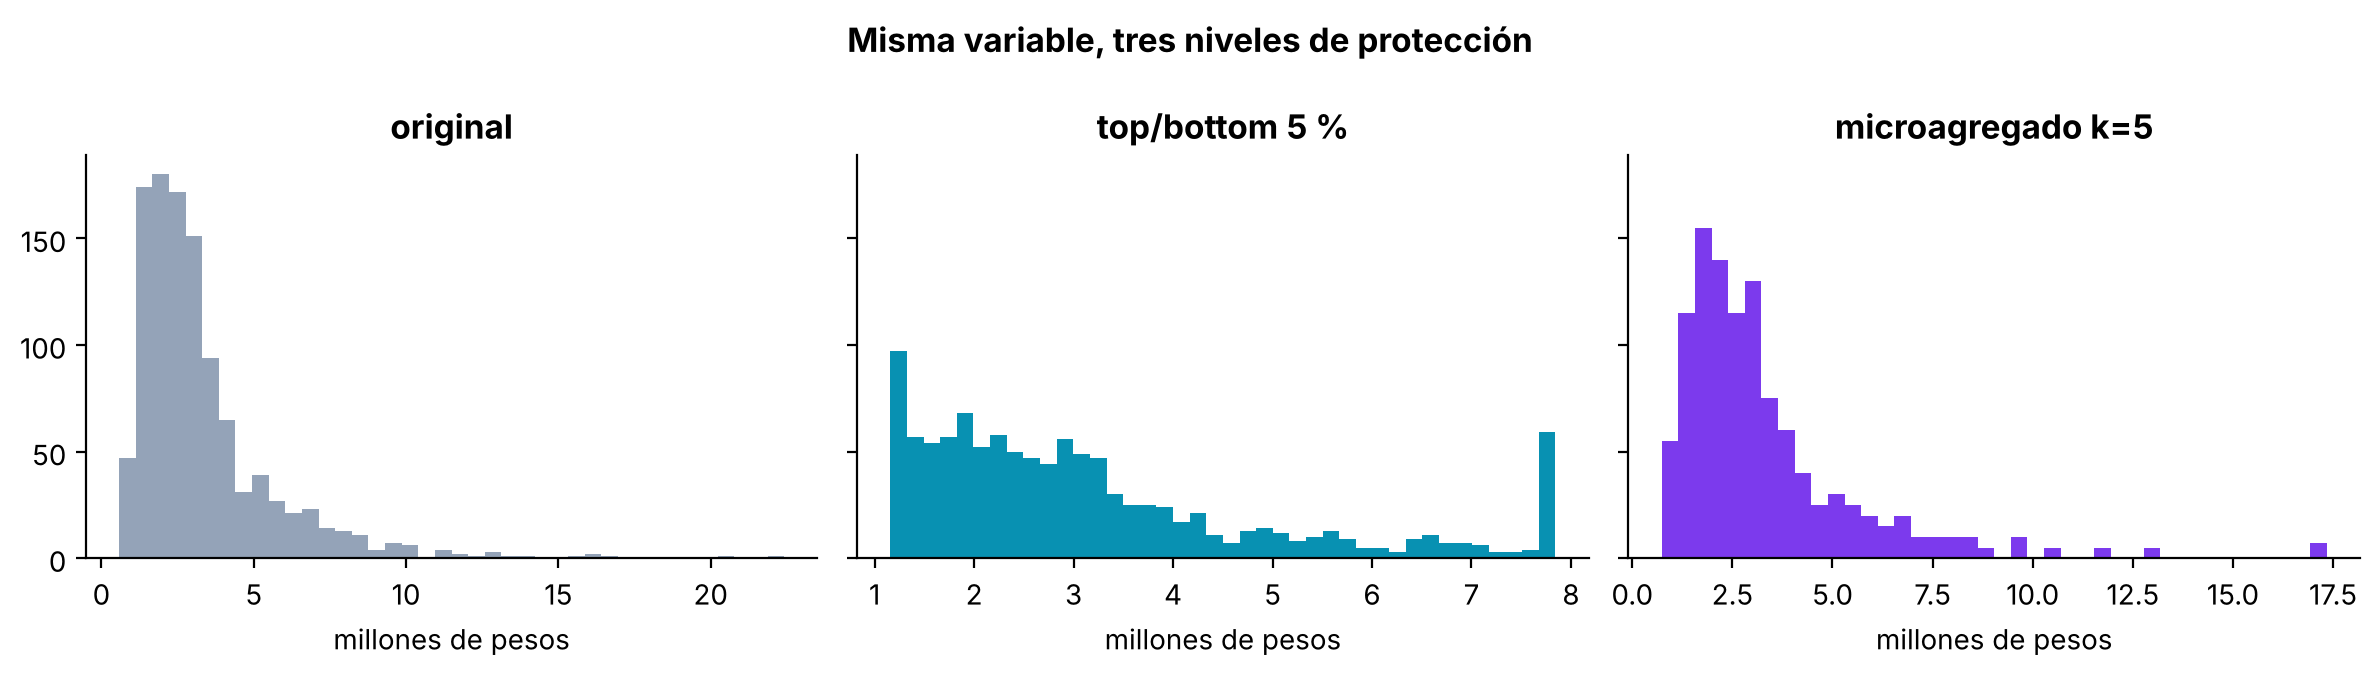

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for a, (nombre, serie), col in zip(ax, versiones_ing.items(), [COLOR["antes"], COLOR["despues"], COLOR["acento"]]):
    a.hist(serie.dropna() / 1e6, bins=40, color=col)
    a.set_title(nombre)
    a.set_xlabel("millones de pesos")
plt.suptitle("Misma variable, tres niveles de protección", fontweight="bold")
plt.tight_layout()
plt.show()

> ### 🟡 Decida · Pregunta 7
>
> La microagregación conserva la media **exactamente**. ¿Qué no conserva? Y si el proveedor quisiera estudiar a los clientes de ingresos más altos, ¿cuál de las dos técnicas le haría más daño?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Conserva la media pero reduce la varianza y la cantidad de valores distintos, y debilita correlaciones con otras variables. El *top coding* destruye la cola superior: si el interés está justamente en los clientes de mayores ingresos, es la técnica que más daño hace.

</details>

**Mi respuesta:** …

## 🔵 🧰 Estación 6 · Perturbación: ruido y coordenadas

Alterar valores de forma controlada. Útil para variables continuas que el
proveedor necesita en escala numérica.

In [21]:
# ===================== PERILLA =====================
RUIDO_MONTO = 0.10      # DESVIACIÓN ESTÁNDAR relativa del ruido: 0.10 no significa «máximo ±10 %»
DECIMALES_COORD = 2     # 4 ≈ 11 m · 3 ≈ 110 m · 2 ≈ 1,1 km · 1 ≈ 11 km
# ===================================================
rng = np.random.default_rng(11)
monto_ruido = df["monto_compras"] * (1 + rng.normal(0, RUIDO_MONTO, len(df)))

cambio = (monto_ruido / df["monto_compras"] - 1).abs()
print(f"Registros con cambio mayor a ±{RUIDO_MONTO:.0%}: {(cambio > RUIDO_MONTO).mean():.0%}  ·  "
      f"mayor a ±{2*RUIDO_MONTO:.0%}: {(cambio > 2*RUIDO_MONTO).mean():.0%}  (normal: ≈32 % y ≈5 %)")
print(f"Media del monto   original: {df['monto_compras'].mean():>12,.0f}   con ruido: {monto_ruido.mean():>12,.0f}")
print(f"Desv. est. del monto original: {df['monto_compras'].std():>12,.0f}   con ruido: {monto_ruido.std():>12,.0f}")
print(f"Correlación monto-compras_6m original: {df['monto_compras'].corr(df['compras_6m']):.3f}"
      f"   con ruido: {monto_ruido.corr(df['compras_6m']):.3f}")

coords = df[["latitud", "longitud"]]
coords_r = coords.round(DECIMALES_COORD)
print(f"\nPuntos distintos con coordenadas originales: {len(coords.drop_duplicates()):,}")
print(f"Puntos distintos con {DECIMALES_COORD} decimales            : {len(coords_r.drop_duplicates()):,}")
k_coord = tam_grupo(coords_r.assign(barrio=df["barrio"]), ["latitud", "longitud", "barrio"])
print(f"Personas solas en su punto + barrio      : {(k_coord == 1).mean()*100:.1f} %")

Registros con cambio mayor a ±10%: 29%  ·  mayor a ±20%: 4%  (normal: ≈32 % y ≈5 %)
Media del monto   original:      364,989   con ruido:      365,530
Desv. est. del monto original:      367,490   con ruido:      371,830
Correlación monto-compras_6m original: 0.661   con ruido: 0.659

Puntos distintos con coordenadas originales: 1,500
Puntos distintos con 2 decimales            : 712
Personas solas en su punto + barrio      : 58.8 %


> ### 🔵 Pruebe · Pregunta 8
>
> Pruebe `DECIMALES_COORD = 1` y `= 3`. ¿Cuántos decimales necesita para que menos del 20 % quede solo en su punto? ¿Le sirve todavía al proveedor una coordenada así, o es mejor entregar solo la región?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Con 3 decimales (≈ 110 m) y el barrio, el 97,6 % queda solo; con 2 (≈ 1 km), el 58,8 %; con 1 decimal (≈ 11 km), el 1,8 %, pero el punto ya equivale casi a la ciudad. A ese nivel la coordenada no aporta nada que la región no dé: es más honesto suprimirla. Además, el ruido de ±3 km que ya tenían los datos **no** las hacía anónimas, como advierte la Actividad 4.

</details>

**Mi respuesta:** …

## 🔵 🧰 Estación 7 · Privacidad diferencial para tablas

Cuando lo que se publica son **conteos** (un tablero, un informe), se puede
sumar ruido calibrado con una garantía matemática. El parámetro **ε (épsilon)**
es el *presupuesto de privacidad*: menor ε, más ruido, más protección.

El mecanismo de Laplace: `conteo publicado = conteo real + Laplace(0, 1/ε)`.
Es la técnica que usó la Oficina del Censo de Estados Unidos para el censo de 2020.

In [22]:
# Pregunta que alguien quiere publicar: ¿cuántos clientes compran sobre todo salud o maternidad, por ciudad?
real = (df.assign(sensible=df["categoria_top"].isin(["salud_bienestar", "bebe_maternidad"]))
          .groupby("ciudad")["sensible"].sum().sort_values())

def laplace(conteos, epsilon, semilla=0):
    r = np.random.default_rng(semilla)
    return (conteos + r.laplace(0, 1 / epsilon, len(conteos))).round().clip(lower=0).astype(int)

tabla_dp = pd.DataFrame({"real": real})
for eps in [0.1, 0.5, 1, 5]:
    tabla_dp[f"ε = {eps}"] = laplace(real, eps).values
tabla_dp

,real,ε = 0.1,ε = 0.5,ε = 1,ε = 5
ciudad,,,,,
Manizales,6,9,7,6,6
Pasto,6,0,5,5,6
Santa Marta,9,0,4,6,8
Ibague,9,0,2,6,8
Bucaramanga,12,22,14,13,12
Cartagena,13,30,16,15,13
Pereira,15,17,15,15,15
Villavicencio,20,26,21,21,20
Cali,23,24,23,23,23


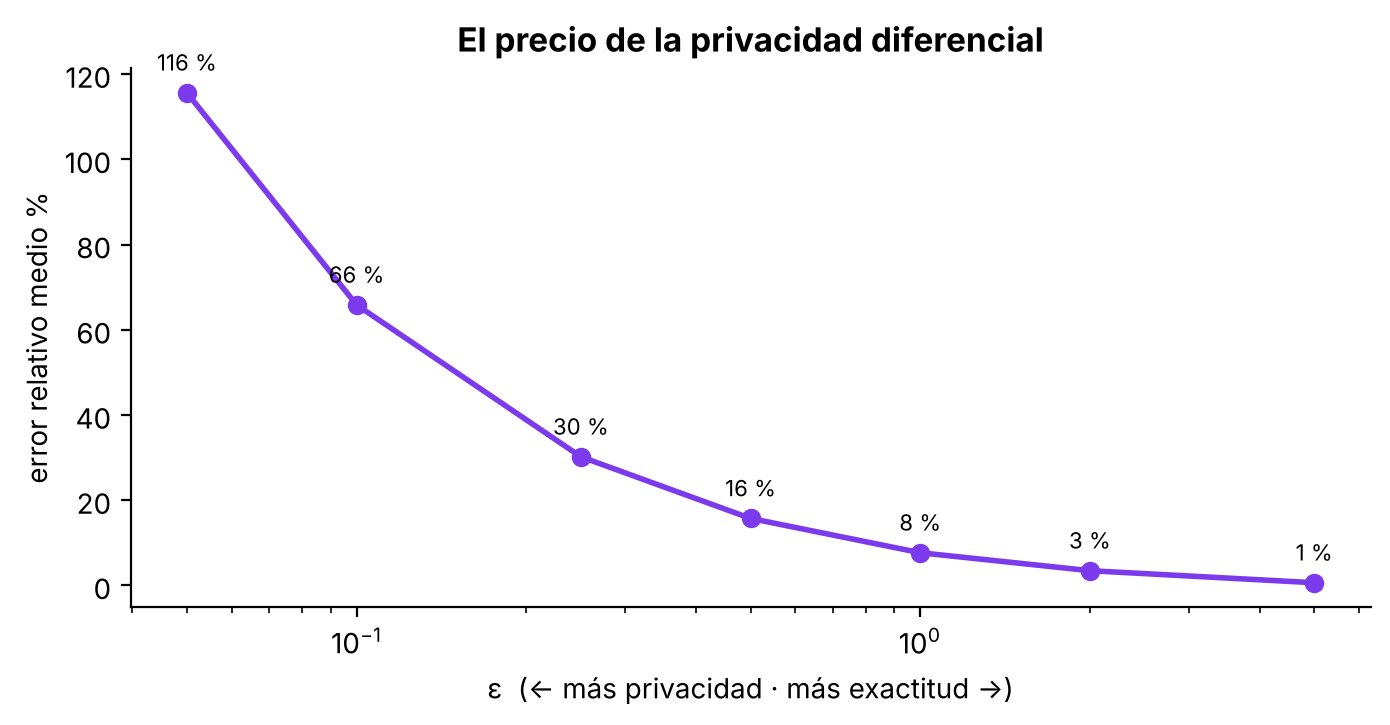

In [23]:
# Error relativo promedio según ε, repitiendo 200 publicaciones.
eps_grid = [0.05, 0.1, 0.25, 0.5, 1, 2, 5]
errores = []
for eps in eps_grid:
    e = [np.mean(np.abs(laplace(real, eps, s) - real) / real) * 100 for s in range(200)]
    errores.append(np.mean(e))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(eps_grid, errores, "o-", color=COLOR["acento"], lw=2)
ax.set_xscale("log")
ax.set_xlabel("ε  (← más privacidad · más exactitud →)")
ax.set_ylabel("error relativo medio %")
ax.set_title("El precio de la privacidad diferencial")
for x, y in zip(eps_grid, errores):
    ax.annotate(f"{y:.0f} %", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
plt.show()

### Tres ideas para no exagerar la garantía

- **Sensibilidad.** Un conteo cambia como máximo en 1 si se agrega o se quita
  una persona. Por eso la escala del ruido es 1/ε. Otras consultas (sumas de
  montos, promedios) tienen sensibilidad mayor y necesitan más ruido.
- **Composición en paralelo.** Cada persona está en una sola ciudad: publicar la
  tabla completa por ciudad gasta **ε una vez**, no doce.
- **Composición secuencial.** Publicar la **misma** tabla *m* veces gasta
  *m* × ε. Las 200 repeticiones del gráfico anterior son una **simulación** del
  error esperado, no publicaciones reales. Si se publicaran, el promedio
  revelaría el valor real, como muestra la celda siguiente.

In [24]:
# Ataque por promedio: publicar 50 veces con ε = 0,5 cada vez equivale a gastar ε = 25.
publicaciones = np.array([laplace(real, 0.5, s) for s in range(50)])
promedio = pd.Series(publicaciones.mean(axis=0), index=real.index).round(1)
pd.DataFrame({"real": real, "una publicación (ε = 0,5)": publicaciones[0],
              "promedio de 50 publicaciones": promedio}).tail(6)

,real,"una publicación (ε = 0,5)",promedio de 50 publicaciones
ciudad,,,
Pereira,15,15,15.4
Villavicencio,20,21,19.9
Cali,23,23,23.0
Barranquilla,31,35,31.6
Medellin,42,44,42.2
Bogota,74,64,73.8


> ### 🟡 Decida · Pregunta 9
>
> Para la ciudad más pequeña el error relativo es mucho mayor que para Bogotá con el mismo ε. ¿Por qué? ¿Qué le dice eso sobre publicar tablas muy desagregadas (por barrio, por vereda)?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

El ruido de Laplace tiene el mismo tamaño absoluto para todas las celdas; en una celda pequeña ese ruido pesa mucho más en términos relativos. Mientras más se desagrega, más ruido relativo, y cada consulta adicional consume presupuesto. Desagregar tiene un precio que se paga en exactitud o en privacidad, no hay tercera opción.

</details>

**Mi respuesta:** …

## 🔵 🧰 Estación 8 · Datos sintéticos

Generar una base **nueva**, sin personas reales, que imite a la original.
Probamos dos generadores muy sencillos y los evaluamos con la prueba estándar
**TSTR**: *entrenar con sintético, evaluar con real*.

> ⚠️ **Regla para no hacer trampa.** Las personas reales con que se evalúa
> **no pueden** haber sido usadas para crear los sintéticos. Por eso partimos la
> base en dos: el 70 % alimenta al generador y el 30 % solo sirve para evaluar.

In [25]:
from sklearn.model_selection import train_test_split

def sintetico_independiente(datos, columnas=COLS_MODELO, n=None, semilla=1):
    # Cada columna se muestrea por separado: conserva marginales, rompe relaciones.
    r = np.random.default_rng(semilla)
    n = n or len(datos)
    return pd.DataFrame({c: r.choice(datos[c].values, n) for c in columnas + ["churn"]})

def sintetico_condicional(datos, columnas=COLS_MODELO, objetivo="churn", semilla=1):
    # Dentro de cada clase de abandono, cada columna se muestrea por separado.
    partes = []
    for valor, sub in datos.groupby(objetivo):
        s = sintetico_independiente(sub, columnas, len(sub), semilla + int(valor))
        s[objetivo] = valor
        partes.append(s)
    return pd.concat(partes, ignore_index=True).sample(frac=1, random_state=semilla)

def auc_holdout(entreno, prueba):
    Xtr = _matriz(entreno, COLS_MODELO); med = Xtr.median()
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5)).fit(Xtr.fillna(med), entreno["churn"])
    return round(roc_auc_score(prueba["churn"], m.predict_proba(_matriz(prueba, COLS_MODELO, Xtr.columns).fillna(med))[:, 1]), 3)

real_gen, real_eval = train_test_split(df, test_size=0.3, stratify=df["churn"], random_state=7)
s_ind = sintetico_independiente(real_gen)
s_con = sintetico_condicional(real_gen)

utilidad_sint = pd.DataFrame({"AUC en el 30 % real no visto": [
    auc_holdout(real_gen, real_eval), auc_holdout(s_ind, real_eval), auc_holdout(s_con, real_eval)]},
    index=["entrenado con el 70 % real (referencia)", "sintético independiente", "sintético condicional"])
utilidad_sint

,AUC en el 30 % real no visto
entrenado con el 70 % real (referencia),0.818
sintético independiente,0.487
sintético condicional,0.781


### ¿El sintético protege? «Cero copias» no basta

Que ninguna fila sintética sea idéntica a una real es una condición mínima, no
una prueba. La pregunta útil es otra: **si un atacante busca en la base
sintética a una persona real que era única, ¿aprende algo sobre ella?**
Comparamos su acierto con el de alguien que simplemente adivina la categoría
más frecuente.

In [26]:
copias = s_con.merge(real_gen[COLS_MODELO + ["churn"]], on=COLS_MODELO + ["churn"]).shape[0]

unicos = real_gen[tam_grupo(real_gen, CUASI) == 1]          # personas reales solas en su grupo
coinc = unicos.merge(s_con, on=CUASI, suffixes=("_real", "_sint"))
acierto = (coinc[SENSIBLE + "_real"] == coinc[SENSIBLE + "_sint"]).mean() * 100
azar = real_gen[SENSIBLE].value_counts(normalize=True).iloc[0] * 100

print(f"Filas sintéticas idénticas a una persona real          : {copias}")
print(f"Personas únicas con al menos un «doble» sintético       : {coinc[CUASI].drop_duplicates().shape[0]} de {len(unicos)}")
print(f"Acierto del atacante sobre la categoría que más compra  : {acierto:.1f} %")
print(f"Acierto adivinando siempre la categoría más frecuente   : {azar:.1f} %")

Filas sintéticas idénticas a una persona real          : 0
Personas únicas con al menos un «doble» sintético       : 110 de 929
Acierto del atacante sobre la categoría que más compra  : 15.7 %
Acierto adivinando siempre la categoría más frecuente   : 20.3 %


> ### 🔴 Riesgo · Pregunta 10
>
> El sintético independiente pierde casi toda la señal; el condicional conserva parte. En la prueba de inferencia, el atacante acierta **menos** que adivinando. ¿Qué pasaría con esa prueba si usáramos un generador mucho más potente (redes neuronales, cópulas), que conserva más relaciones?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Con un generador potente la utilidad sube, pero también el riesgo de que **memorice**: puede reproducir registros reales casi idénticos, sobre todo de personas atípicas, y entonces el acierto del atacante superaría al azar. Por eso un sintético no es anónimo por definición: hay que medir copias, inferencia de atributos y, en estudios serios, ataques de pertenencia. Nuestro generador es tan simple que no puede memorizar combinaciones; eso explica su baja utilidad y su bajo riesgo.

</details>

**Mi respuesta:** …

---

# 4 · COMPARAR

*Cinco bases candidatas, dos escenarios de atacante y una utilidad medida sin trampas.*

### Cómo se mide cada eje

| Eje | Medida | Cómo se lee |
|:--|:--|:--|
| Riesgo | % *k*<5 y riesgo 1/*k*, en el escenario **básico** y en el **ampliado** | El ampliado es el que decide: el estrato viaja en la base |
| Riesgo | % reidentificado por el **ataque** de vinculación | Personas de la fuente pública acertadas con certeza |
| Pérdida | **NCP %** | 0 = exacto · 100 = suprimido |
| Utilidad | **AUC** del modelo de abandono, 5 pliegues | Media ± desviación estándar entre pliegues |
| Utilidad | **ΔAUC** frente a V0, pareado (mismos pliegues) | Regla práctica, no una prueba formal: si ΔAUC, en valor absoluto, es menor que su desviación, **no hay diferencia demostrable** |
| Utilidad | **Δ tasa** de abandono por categoría | Cuánto se deforma una estadística descriptiva (pp) |

**Sin fugas:** en cada pliegue, la generalización, la supresión o el generador
sintético se aplican **solo** al 80 % de entrenamiento; el 20 % restante son
personas reales nuevas, a las que se aplica la misma regla de generalización
(sin suprimirlas, porque en la vida real siguen existiendo).

In [27]:
VERSIONES = {
    "V0 · sin identificadores":          dict(gen=None, sup=None),
    "V1 · generalización suave":         dict(gen=(5, "conservar", "ciudad", "grupo", "exacto"), sup=None),
    "V2 · fuerte + supresión (básico)":  dict(gen=(10, "agrupar", "region", "grupo", "exacto"), sup=CUASI),
    "V2b · fuerte + estrato en niveles": dict(gen=(10, "agrupar", "region", "suprimir", "nivel"), sup=CUASI_AMPLIADO),
    "V3 · sintética condicional":        dict(sint=True),
    "★ su versión (estaciones 3+4)":     dict(gen=(NIVEL_EDAD, SEXO_COMO, CIUDAD_COMO, OCUPACION_COMO, ESTRATO_COMO),
                                              sup=CUASI_AMPLIADO),
}

def construir(cfg, datos=e1):
    d = generalizar(datos, *cfg["gen"]) if cfg.get("gen") else datos
    return d[tam_grupo(d, cfg["sup"]) >= K_OBJETIVO] if cfg.get("sup") else d

candidatas, filas, aucs = {}, [], {}
for nombre, cfg in VERSIONES.items():
    if cfg.get("sint"):
        base = sintetico_condicional(df)
        aucs[nombre] = utilidad_cv(sintetico=lambda tr: sintetico_condicional(tr))
        fila = {"registros": len(base), "% k<5 básico": np.nan, "% k<5 ampliado": np.nan,
                "riesgo 1/k % ampliado": np.nan, "% reid. ataque básico": 0.0,
                "% reid. ataque ampliado": 0.0, "NCP %": np.nan}
    else:
        base = construir(cfg)
        pub = generalizar(fuente_publica, *cfg["gen"]) if cfg.get("gen") else fuente_publica
        trans = (lambda d, g=cfg.get("gen"): generalizar(d, *g)) if cfg.get("gen") else None
        aucs[nombre] = utilidad_cv(transformar=trans, suprimir_en=cfg.get("sup"))
        b, a = perfil_riesgo(base, CUASI), perfil_riesgo(base, CUASI_AMPLIADO)
        fila = {"registros": len(base), "% k<5 básico": b["% k<5"], "% k<5 ampliado": a["% k<5"],
                "riesgo 1/k % ampliado": a["riesgo medio 1/k %"],
                "% reid. ataque básico": ataque_vinculacion(pub, base, CUASI, mostrar=False)[0]["% reidentificadas"],
                "% reid. ataque ampliado": ataque_vinculacion(pub, base, CUASI_AMPLIADO, mostrar=False)[0]["% reidentificadas"],
                "NCP %": ncp(base)}
    candidatas[nombre] = base
    d = aucs[nombre] - aucs["V0 · sin identificadores"]
    fila.update({"Δ tasa abandono (pp)": dif_tasas(base),
                 "AUC": f"{aucs[nombre].mean():.3f} ± {aucs[nombre].std():.3f}",
                 "ΔAUC vs V0": f"{d.mean():+.3f} ± {d.std():.3f}" if nombre[:2] != "V0" else "—"})
    filas.append({"versión": nombre, **fila})

frontera = pd.DataFrame(filas).set_index("versión")
frontera

,registros,% k<5 básico,% k<5 ampliado,riesgo 1/k % ampliado,% reid. ataque básico,% reid. ataque ampliado,NCP %,Δ tasa abandono (pp),AUC,ΔAUC vs V0
versión,,,,,,,,,,
V0 · sin identificadores,1512,100.0,100.0,97.8,82.7,94.0,0.0,0.0,0.823 ± 0.033,—
V1 · generalización suave,1512,63.2,98.3,76.0,21.0,55.7,7.9,0.0,0.818 ± 0.040,-0.005 ± 0.008
V2 · fuerte + supresión (básico),1226,0.0,65.3,40.5,0.0,14.0,29.6,2.9,0.818 ± 0.046,-0.005 ± 0.015
V2b · fuerte + estrato en niveles,1205,0.0,0.0,8.2,0.0,0.0,44.3,6.8,0.808 ± 0.031,-0.016 ± 0.011
V3 · sintética condicional,1512,NaN,NaN,NaN,0.0,0.0,NaN,4.6,0.796 ± 0.033,-0.027 ± 0.014
★ su versión (estaciones 3+4),1205,0.0,0.0,8.2,0.0,0.0,44.3,6.8,0.808 ± 0.031,-0.016 ± 0.011


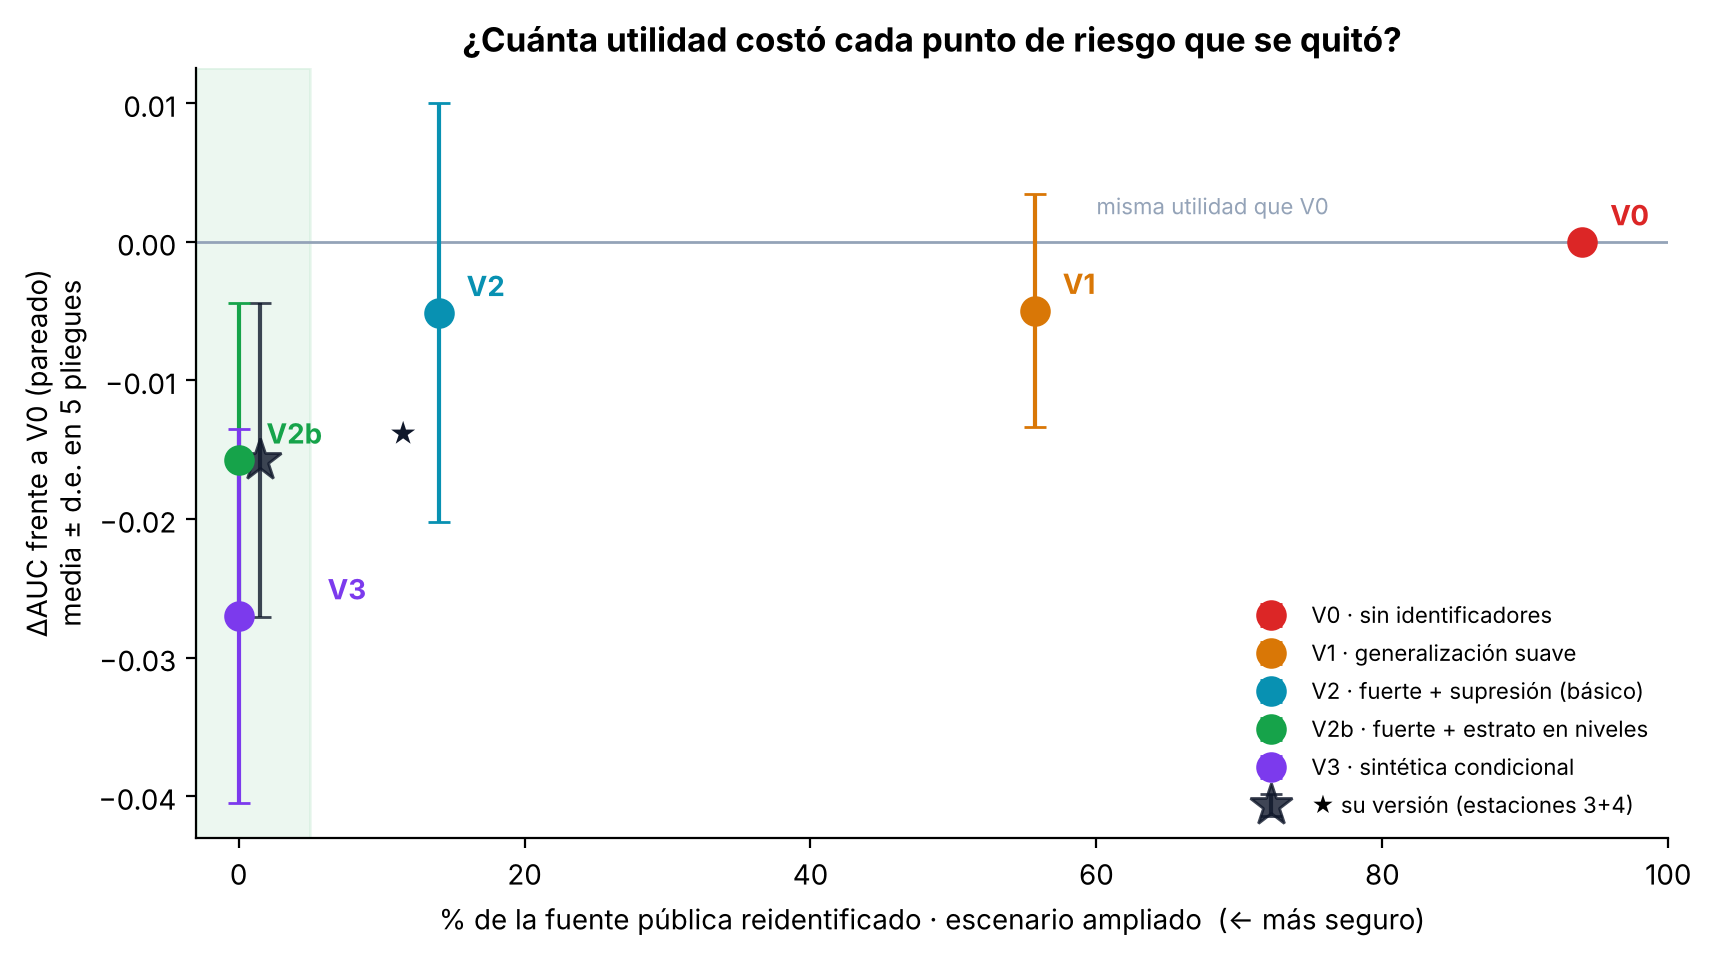

In [28]:
fig, ax = plt.subplots(figsize=(9.5, 5))
colores = [COLOR["alerta"], COLOR["ambar"], COLOR["despues"], COLOR["ok"], COLOR["acento"], "#0f172a"]
usados = {}
for (nombre, fila), col in zip(frontera.iterrows(), colores):
    d = aucs[nombre] - aucs["V0 · sin identificadores"]
    x, y, e = fila["% reid. ataque ampliado"], d.mean(), d.std()
    es_mia = nombre.startswith("★")
    ax.errorbar(x + (1.5 if es_mia else 0), y, yerr=e, fmt="*" if es_mia else "o", ms=16 if es_mia else 10,
                color=col, capsize=4, label=nombre, zorder=2 if es_mia else 3, alpha=.8 if es_mia else 1)
    k = round(x / 6)
    usados[k] = usados.get(k, -1) + 1
    corto = "★" if nombre.startswith("★") else nombre.split(" · ")[0]
    ax.annotate(corto, (x, y), textcoords="offset points", xytext=(10 + 22 * usados[k], 6),
                fontsize=10, fontweight="bold", color=col)
ax.axhline(0, color=COLOR["antes"], lw=1)
ax.text(60, 0.002, "misma utilidad que V0", fontsize=8, color=COLOR["antes"])
ax.axvspan(-3, 5, color=COLOR["ok"], alpha=.08)
ax.set_xlim(-3, 100)
ax.set_xlabel("% de la fuente pública reidentificado · escenario ampliado  (← más seguro)")
ax.set_ylabel("ΔAUC frente a V0 (pareado)\nmedia ± d.e. en 5 pliegues")
ax.set_title("¿Cuánta utilidad costó cada punto de riesgo que se quitó?")
ax.legend(frameon=False, loc="lower right", fontsize=8)
plt.show()

### ¿Qué técnicas llegaron a las versiones finales?

| Estación | ¿Está en V2 / V2b? | Por qué |
|:--|:--|:--|
| 1 · Supresión de indirectos | Sí | IP, coordenadas, barrio y fecha de nacimiento no viajan |
| 2 · Seudonimización | No en la base: se entrega un identificador aleatorio | El proveedor no necesita unir con otras tablas; si lo necesitara, HMAC |
| 3 · Generalización | Sí | Edad, sexo, ciudad, ocupación y (en V2b) estrato |
| 4 · Supresión local | Sí | Los grupos con *k* < 5 |
| 5 · *Top coding* / microagregación | No | `ingresos_mensuales` no se entrega: minimizar fue más barato |
| 6 · Perturbación | No | Las coordenadas no se entregan. **`monto_compras` sí, exacto**: riesgo residual que hay que declarar |
| 7 · Privacidad diferencial | No | Sirve para publicar tablas, no para entregar microdatos |
| 8 · Datos sintéticos | Es la versión V3 | Alternativa completa, no un paso |

> ### 🟣 Decisión · Pregunta 11
>
> Compare V2 y V2b. V2 parece perfecta en el escenario básico. ¿Qué le pasa cuando el atacante también conoce el estrato? Luego mire la columna `ΔAUC vs V0`: ¿hay alguna versión con una pérdida de utilidad **demostrable**?
>
> La pregunta central del encuentro: **¿cuánta utilidad estamos dispuestos a perder, y quién decide eso?**

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

V2 cumple *k* ≥ 5 con cuatro cuasi-identificadores, pero entrega el estrato exacto: con él, la mayoría de los registros vuelve a quedar en grupos pequeños y el ataque ampliado reidentifica a muchas personas. **Una métrica sin escenario declarado no prueba nada.** V2b corrige eso generalizando el estrato y suprimiendo la ocupación, a cambio de más pérdida (NCP ≈ 44 %), unos 300 registros suprimidos y tasas descriptivas deformadas hasta unos 7 puntos. En utilidad predictiva, V1 y V2 pierden ≈ 0,005 de AUC, menos que su desviación: no es una diferencia demostrable. V2b pierde ≈ 0,016 ± 0,011 y el sintético ≈ 0,027 ± 0,014: pérdidas **pequeñas pero consistentes**. Conclusión honesta: proteger de verdad sí cuesta, pero menos de lo que se teme, y solo se sabe midiendo. Quién decide: el responsable del tratamiento, con el umbral y el escenario escritos.

</details>

**Mi respuesta:** …

---

# 5 · DECIDIR Y ENTREGAR

*Una base concreta, un umbral escrito, un escenario declarado y un informe que
otra persona pueda auditar.*

In [29]:
pd.DataFrame(BITACORA).set_index("paso")

,técnica,registros,k mín. (básico),% k<5 (básico),% k<5 (+estrato),riesgo 1/k % (+estrato),% homogéneos,NCP %,nota
paso,,,,,,,,,
0 · sin identificadores directos,supresión de 5 columnas,1512,1,100.0,100.0,97.8,3.2,0.0,lo que casi todos entregan
3 · generalización (mía),generalización,1512,1,4.6,20.3,17.5,0.1,30.0,edad 10 · sexo agrupar · region · ocupación su...
4 · + supresión local k<5,supresión de registros,1205,5,0.0,0.0,8.2,0.0,44.3,307 registros fuera


In [30]:
# ===================== PERILLA =====================
VERSION_ELEGIDA = "V2b · fuerte + estrato en niveles"
SALIDA = "1 · base anonimizada con utilidad reducida"
FINALIDAD = "Entrenar y validar el motor de recomendación de DataMarket; ningún otro uso."
POR_QUE_MICRODATOS = ("El motor aprende de patrones individuales de compra; los agregados no sirven y "
                      "el sintético simple pierde parte de la señal.")
UMBRAL = "k ≥ 5 para el 100 % de los registros en el escenario ampliado y <5 % reidentificado en el ataque"
JUSTIFICACION = ("V2b es la única versión de microdatos que cumple en los dos escenarios declarados. "
                 "Cuesta una pérdida pequeña pero consistente de AUC (≈ 0,016), detalle demográfico y "
                 "unos 300 registros suprimidos, que se reportan con su perfil.")
CONDICIONES = ("Acuerdo de transmisión con prohibición de cruce y de reidentificación; uso exclusivo para la "
               "finalidad; ambiente controlado; destrucción a los 6 meses; auditoría.")
EQUIPO = "Docente · versión de referencia"
# ===================================================

In [31]:
f = frontera.loc[VERSION_ELEGIDA]
v0 = frontera.iloc[0]

# ---- Verificación automática antes de exportar --------------------------------
es_sintetica = pd.isna(f["% k<5 ampliado"])
chequeos = {
    "k ≥ 5 para todos (escenario básico)": es_sintetica or f["% k<5 básico"] == 0,
    "k ≥ 5 para todos (escenario ampliado)": es_sintetica or f["% k<5 ampliado"] == 0,
    "ataque ampliado < 5 %": f["% reid. ataque ampliado"] < 5,
    "sin identificadores directos ni indirectos": not set(IDENTIFICADORES_DIRECTOS + INDIRECTOS) & set(candidatas[VERSION_ELEGIDA].columns),
}
cumple = all(chequeos.values())
for k_, v_ in chequeos.items():
    print(("✅ " if v_ else "❌ ") + k_)
if not cumple and SALIDA.startswith("1"):
    print("\n⚠️  La versión NO cumple el umbral para la salida 1. Cambie de versión o de salida "
          "(2: bajo contrato · 3: no entregar). El informe quedará marcado.")
dictamen = ("LIBERAR CON CONDICIONES" if cumple and SALIDA.startswith("1")
            else "NO LIBERAR COMO ANONIMIZADA" if SALIDA.startswith("1")
            else "ENTREGA BAJO CONTRATO (datos personales)" if SALIDA.startswith("2")
            else "NO SE ENTREGA LA BASE")

entregable = candidatas[VERSION_ELEGIDA][[c for c in COLS_MODELO + ["churn"] if c in candidatas[VERSION_ELEGIDA].columns]].copy()
entregable = entregable.loc[:, entregable.nunique() > 1]   # columnas suprimidas (todo «*») no viajan
entregable.insert(0, "id_entrega", [secrets.token_hex(6) for _ in range(len(entregable))])  # sin vínculo posible
entregable.to_csv("base_entregable_proveedor.csv", index=False, encoding="utf-8")

informe = f'''# Dictamen de liberación de datos · DataMarket → proveedor

**Equipo:** {EQUIPO}  ·  **Fecha:** {pd.Timestamp("today").date()}  ·  **Dictamen:** {dictamen}

## 1. Finalidad y necesidad
- Finalidad: {FINALIDAD}
- ¿Por qué microdatos?: {POR_QUE_MICRODATOS}

## 2. Qué se entrega
- Versión: **{VERSION_ELEGIDA}** · salida elegida: **{SALIDA}**
- {len(entregable)} registros de {len(df)} ({len(df) - len(entregable)} suprimidos) · {entregable.shape[1]} variables: {", ".join(entregable.columns)}

## 3. Qué se midió
Escenario básico: el atacante conoce edad, sexo, ciudad y ocupación. Escenario ampliado: además, el estrato.

| Métrica | Línea base (V0) | Entregable |
|:--|--:|--:|
| % registros con k<5 · básico | {v0["% k<5 básico"]} | {f["% k<5 básico"]} |
| % registros con k<5 · ampliado | {v0["% k<5 ampliado"]} | {f["% k<5 ampliado"]} |
| Riesgo medio 1/k % · ampliado | {v0["riesgo 1/k % ampliado"]} | {f["riesgo 1/k % ampliado"]} |
| % reidentificado en el ataque · ampliado | {v0["% reid. ataque ampliado"]} | {f["% reid. ataque ampliado"]} |
| Pérdida de información NCP % | {v0["NCP %"]} | {f["NCP %"]} |
| AUC del modelo de abandono (5 pliegues) | {v0["AUC"]} | {f["AUC"]} |
| ΔAUC frente a V0 (pareado) | — | {f["ΔAUC vs V0"]} |
| Máx. cambio en la tasa de abandono por categoría (pp) | 0 | {f["Δ tasa abandono (pp)"]} |

Verificación automática: {"; ".join(("cumple: " if v else "NO cumple: ") + k for k, v in chequeos.items())}.

## 4. Umbral aceptado y por qué
{UMBRAL}. {JUSTIFICACION}

## 5. Riesgo residual
Vale solo para los dos escenarios declarados. No cubre a un atacante que conozca montos o fechas de
compra exactos (`monto_compras` viaja sin perturbar) ni el cruce con otras bases del proveedor. El
riesgo 1/k supone que el atacante sabe que la persona está en la base.

## 6. Condiciones de la entrega
{CONDICIONES}
'''
with open("informe_anonimizacion.md", "w", encoding="utf-8") as fh:
    fh.write(informe)

from IPython.display import Markdown, display
display(Markdown(informe))
print("Archivos creados: base_entregable_proveedor.csv · informe_anonimizacion.md")

✅ k ≥ 5 para todos (escenario básico)
✅ k ≥ 5 para todos (escenario ampliado)
✅ ataque ampliado < 5 %
✅ sin identificadores directos ni indirectos


# Dictamen de liberación de datos · DataMarket → proveedor

**Equipo:** Docente · versión de referencia  ·  **Fecha:** 2026-11-10  ·  **Dictamen:** LIBERAR CON CONDICIONES

## 1. Finalidad y necesidad
- Finalidad: Entrenar y validar el motor de recomendación de DataMarket; ningún otro uso.
- ¿Por qué microdatos?: El motor aprende de patrones individuales de compra; los agregados no sirven y el sintético simple pierde parte de la señal.

## 2. Qué se entrega
- Versión: **V2b · fuerte + estrato en niveles** · salida elegida: **1 · base anonimizada con utilidad reducida**
- 1205 registros de 1512 (307 suprimidos) · 13 variables: id_entrega, edad, sexo, ciudad, estrato, visitas_web, productos_vistos, compras_6m, monto_compras, recencia_dias, canal_adquisicion, categoria_top, churn

## 3. Qué se midió
Escenario básico: el atacante conoce edad, sexo, ciudad y ocupación. Escenario ampliado: además, el estrato.

| Métrica | Línea base (V0) | Entregable |
|:--|--:|--:|
| % registros con k<5 · básico | 100.0 | 0.0 |
| % registros con k<5 · ampliado | 100.0 | 0.0 |
| Riesgo medio 1/k % · ampliado | 97.8 | 8.2 |
| % reidentificado en el ataque · ampliado | 94.0 | 0.0 |
| Pérdida de información NCP % | 0.0 | 44.3 |
| AUC del modelo de abandono (5 pliegues) | 0.823 ± 0.033 | 0.808 ± 0.031 |
| ΔAUC frente a V0 (pareado) | — | -0.016 ± 0.011 |
| Máx. cambio en la tasa de abandono por categoría (pp) | 0 | 6.8 |

Verificación automática: cumple: k ≥ 5 para todos (escenario básico); cumple: k ≥ 5 para todos (escenario ampliado); cumple: ataque ampliado < 5 %; cumple: sin identificadores directos ni indirectos.

## 4. Umbral aceptado y por qué
k ≥ 5 para el 100 % de los registros en el escenario ampliado y <5 % reidentificado en el ataque. V2b es la única versión de microdatos que cumple en los dos escenarios declarados. Cuesta una pérdida pequeña pero consistente de AUC (≈ 0,016), detalle demográfico y unos 300 registros suprimidos, que se reportan con su perfil.

## 5. Riesgo residual
Vale solo para los dos escenarios declarados. No cubre a un atacante que conozca montos o fechas de
compra exactos (`monto_compras` viaja sin perturbar) ni el cruce con otras bases del proveedor. El
riesgo 1/k supone que el atacante sabe que la persona está en la base.

## 6. Condiciones de la entrega
Acuerdo de transmisión con prohibición de cruce y de reidentificación; uso exclusivo para la finalidad; ambiente controlado; destrucción a los 6 meses; auditoría.


Archivos creados: base_entregable_proveedor.csv · informe_anonimizacion.md


> ### 🟣 Decisión · Pregunta 12
>
> El dictamen dice «riesgo residual: vale para los escenarios declarados». Nombre **un escenario de ataque** que su medición no cubre y diga qué condición contractual o técnica lo compensaría.

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Ejemplos: el proveedor tiene su propia base con montos y fechas de compra (puede vincular por comportamiento, no por demografía) → perturbar o redondear `monto_compras`, prohibición contractual de cruce, auditoría y ambiente controlado. O una filtración en el proveedor → cifrado, acceso por rol y plazo de destrucción. Lo que se busca es que el estudiante reconozca que **la métrica depende del escenario** y que el contrato cubre lo que la técnica no alcanza.

</details>

**Mi respuesta:** …

---

# 6 · REFLEXIONAR

*Lo que cambia con el volumen y con los modelos.*

| Con Big Data… | Con IA… |
|:--|:--|
| Más variables = más cuasi-identificadores: la unicidad **crece**, no se diluye | El modelo entrenado puede **memorizar** y devolver datos personales |
| Las trazas (ubicación, compras, búsquedas) son únicas: 4 puntos de ubicación bastan para identificar al 95 % de las personas (de Montjoye, 2013) | Un **ataque de pertenencia** puede revelar si alguien estaba en el entrenamiento |
| Cada cruce nuevo es un ataque de vinculación potencial | El modelo pasa a ser un **activo que contiene datos** y hereda sus obligaciones |

> ### 🟢 Reflexione · Pregunta 13
>
> El proveedor no quiere la base: quiere **entrenar un modelo** con ella. Si entrega V0 y él entrena un modelo muy grande, ¿la base deja de importar cuando se borra? ¿Qué pediría en el contrato sobre el **modelo**, no solo sobre los datos?

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

No: el modelo puede conservar información de las personas y exponerla. En el contrato: uso exclusivo del modelo para la finalidad, prohibición de reutilizarlo o venderlo, destrucción o reentrenamiento si se revoca la autorización, pruebas de memorización antes del despliegue y la alternativa más fuerte: entrenar dentro del perímetro de DataMarket sin que los datos salgan.

</details>

**Mi respuesta:** …

> ### 🟢 Reflexione · Pregunta 14
>
> **Aporte al decálogo (Encuentro 5).** Escriba **una regla** para el decálogo del científico de datos que salga de este laboratorio.
>
> Formato: *verbo en imperativo + qué + evidencia que queda*. Ejemplo: «Mida el riesgo de reidentificación antes y después de transformar, y deje la bitácora con la entrega».

✍️ *Escriba su respuesta en la celda de abajo antes de seguir.*

<details><summary><b>Respuesta orientativa (versión docente)</b></summary>

Se busca una regla ejecutable y verificable. Otras buenas: «Ataque su base antes de entregarla»; «Nunca use un *hash* sin clave como seudónimo»; «Revise a quién se lleva la supresión».

</details>

**Mi respuesta:** …

---

## Lo que queda del laboratorio

| Archivo | Para qué |
|:--|:--|
| `base_entregable_proveedor.csv` | La base que saldría hacia el proveedor |
| `informe_anonimizacion.md` | El dictamen de liberación: borrador del informe de la **Actividad 4** |
| La bitácora y la frontera riesgo-utilidad | La evidencia de que se midió |

### Las ocho técnicas en una línea

| Técnica | Protege | Cuesta |
|:--|:--|:--|
| Supresión de variables | Cierra puertas de vinculación | Todo el análisis que dependía de ellas |
| Seudonimización (HMAC) | El identificador | Nada… y **no anonimiza** |
| Generalización | Identidad (*k*) | Resolución analítica |
| Supresión local | Los casos raros | Sesgo: borra minorías |
| *Top coding* / microagregación | Valores extremos | Colas y varianza |
| Ruido | Valores exactos | Distribuciones y correlaciones |
| Privacidad diferencial | Tablas publicadas, con garantía | Exactitud en celdas pequeñas |
| Datos sintéticos | Todo, si no memoriza | Relaciones que el generador no captura |

**Siguiente paso:** Actividad 4 (en grupo, semana 8) y Encuentro 5 · el decálogo.

**Marco legal relacionado:** art. 10 de la Ley 1581 de 2012 (fines
estadísticos), considerando 26 del GDPR (datos anónimos frente a
seudonimizados), arts. 36 a 40 de la Ley 2335 de 2023 (reserva estadística).